# Healthcare Claims EDA & Cost Analysis
**CMS DE-SynPUF Medicare Claims | 2008-2010 | 230M+ Records**

*Alessandro Sousa* - November 2026

---

**Objective:** Answer six core business questions a US health plan asks every quarter - where the money goes, for whom, and what's avoidable - using 230 million synthetic Medicare claims processed with DuckDB.

| # | Business Question | Section |
|---|---|---|
| 1 | What share of total spend comes from the costliest members? | S4 Cost Concentration |
| 2 | What is the PMPM cost by service line, and how does it trend? | S5 PMPM by Service Line |
| 3 | How does chronic-condition layering drive cost? | S6 Chronic Conditions |
| 4 | What is the 30-day readmission rate, and what drives it? | S7 Avoidable Utilization |
| 5 | How does cost vary by age and sex? | S8 Age-Sex Cost Curves |
| 6 | What are the top cost drivers by DRG, HCPCS, and drug category? | S9 Top Cost Drivers |

## S0 - Setup

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# src/ on path
sys.path.insert(0, str(Path.cwd().parent))

from src.config          import *
from src.data_loader     import get_connection, create_views, create_beneficiary_enriched, row_count
from src.quality         import compute_completeness, print_completeness_tiers, check_referential_integrity, check_temporal_consistency
from src.visual_identity import (
    visual_identity, fig_title, adjust_axis, auto_scale_axis,
    fmt_num, fmt_usd, bar_labels, render_table,
    ECON_BG, ECON_RED, NATURE_TEAL, NATURE_CORAL, DEEP_BLUE,
    AMBER, PLUM, WARM_GREY, CHARCOAL, LIGHT_GREY,
    PALETA_SEQ, WHITE
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# DuckDB connection & views─
con = get_connection(memory_limit="6GB", threads=4)
create_views(con)

print("✓ Views created for:", list(DESYNPUF_PATHS.keys()))
print(f"✓ DuckDB ready  ·  memory_limit = 6 GB  ·  threads = 4")

✓ Views created for: ['beneficiary', 'inpatient', 'outpatient', 'carrier', 'pde']
✓ DuckDB ready  ·  memory_limit = 6 GB  ·  threads = 4


## S1 - Data Quality Assessment

Before any analysis, we validate the data across three dimensions:
1. **Volume** - do row counts match expectations?
2. **Completeness** - what's the fill rate per column?
3. **Referential integrity** - do foreign keys resolve?
4. **Temporal consistency** - are date ranges plausible?

In [32]:
# 1a. Volume check
print("TABLE VOLUME CHECK")
print("=" * 60)
for table, expected in EXPECTED_ROWS.items():
    actual = row_count(con, table)
    status = "✓" if actual == expected else "✗"
    delta  = actual - expected
    print(f"  {status} {table:<14s}  {actual:>14,}  (expected {expected:>14,}, Δ {delta:+,})")

TABLE VOLUME CHECK
  ✓ beneficiary          6,873,274  (expected      6,873,274, Δ +0)
  ✓ carrier             94,863,452  (expected     94,863,452, Δ +0)
  ✓ inpatient            1,332,822  (expected      1,332,822, Δ +0)
  ✓ outpatient          15,826,987  (expected     15,826,987, Δ +0)
  ✓ pde                111,085,969  (expected    111,085,969, Δ +0)


In [33]:
# 1b. Completeness by table
for table in ["beneficiary", "inpatient", "outpatient", "carrier", "pde"]:
    print(f"\n{'─'*60}")
    print(f"COMPLETENESS: {table.upper()}")
    print(f"{'─'*60}")
    df_c = compute_completeness(con, table, exclude_prefixes=[])
    print_completeness_tiers(df_c, max_per_tier=20)


────────────────────────────────────────────────────────────
COMPLETENESS: BENEFICIARY
────────────────────────────────────────────────────────────
Completeness summary (34 columns):

  100% complete: 33 columns
    DESYNPUF_ID                              100.00%
    BENE_BIRTH_DT                            100.00%
    BENE_SEX_IDENT_CD                        100.00%
    BENE_RACE_CD                             100.00%
    BENE_ESRD_IND                            100.00%
    SP_STATE_CODE                            100.00%
    BENE_COUNTY_CD                           100.00%
    BENE_HI_CVRAGE_TOT_MONS                  100.00%
    BENE_SMI_CVRAGE_TOT_MONS                 100.00%
    BENE_HMO_CVRAGE_TOT_MONS                 100.00%
    PLAN_CVRG_MOS_NUM                        100.00%
    SP_ALZHDMTA                              100.00%
    SP_CHF                                   100.00%
    SP_CHRNKIDN                              100.00%
    SP_CNCR                                  

In [34]:
# 1c. Referential integrity
print("REFERENTIAL INTEGRITY CHECKS")
print("=" * 60)

ri_checks = [
    ("inpatient",  "beneficiary", "DESYNPUF_ID", "DESYNPUF_ID", "Inpatient → Beneficiary"),
    ("outpatient", "beneficiary", "DESYNPUF_ID", "DESYNPUF_ID", "Outpatient → Beneficiary"),
    ("carrier",    "beneficiary", "DESYNPUF_ID", "DESYNPUF_ID", "Carrier → Beneficiary"),
    ("pde",        "beneficiary", "DESYNPUF_ID", "DESYNPUF_ID", "PDE → Beneficiary"),
]

for left, right, lk, rk, desc in ri_checks:
    check_referential_integrity(con, left, right, lk, rk, desc)

REFERENTIAL INTEGRITY CHECKS


In [35]:
# 1d. Temporal consistency
print("TEMPORAL CONSISTENCY CHECKS")
print("=" * 60)

tc_checks = [
    ("inpatient",  "CLM_FROM_DT",  "CLM_THRU_DT",  "2008-01-01", "2010-12-31"),
    ("outpatient", "CLM_FROM_DT",  "CLM_THRU_DT",  "2008-01-01", "2010-12-31"),
    ("carrier",    "CLM_FROM_DT",  "CLM_THRU_DT",  "2008-01-01", "2010-12-31"),
    ("pde",        "SRVC_DT",       None,           "2008-01-01", "2010-12-31"),
]

for table, date_from, date_thru, exp_min, exp_max in tc_checks:
    if date_thru:
        check_temporal_consistency(con, table, date_from, date_thru, exp_min, exp_max)
    else:
        # PDE has only a single service date (SRVC_DT).
        # DE-SynPUF stores dates as YYYYMMDD integers (BIGINT), so we
        # cast to VARCHAR then parse to DATE before comparing to date literals.
        date_cast = (
            f"COALESCE(TRY_CAST({date_from} AS DATE), "
            f"TRY_STRPTIME(CAST({date_from} AS VARCHAR), '%Y%m%d')::DATE)"
        )
        result = con.execute(f"""
            SELECT
                MIN({date_cast})::VARCHAR AS min_dt,
                MAX({date_cast})::VARCHAR AS max_dt,
                SUM(CASE WHEN {date_cast} < DATE '{exp_min}'
                           OR {date_cast} > DATE '{exp_max}'
                         THEN 1 ELSE 0 END) AS out_of_range
            FROM {table}
            WHERE {date_from} IS NOT NULL
        """).fetchdf()
        r = result.iloc[0]
        oor = int(r["out_of_range"])
        status = "✓" if oor == 0 else f"✗ ({oor:,} out of range)"
        print(f"  {status}  {table}.{date_from}: [{r['min_dt']} ... {r['max_dt']}]")

TEMPORAL CONSISTENCY CHECKS


  ✓  pde.SRVC_DT: [2008-01-01 ... 2010-12-31]


### S1 Summary

> **Data quality verdict:** The DE-SynPUF dataset is synthetic by design - CMS generated it for research and education. We expect full referential integrity across all joins and dates within the 2008-2010 window. Completeness gaps in optional fields (e.g., diagnosis codes 4-10, secondary procedures) reflect clinical reality: not every claim carries the maximum number of codes.

---

## S2 - Population Overview

Before diving into cost, understand who's in the data: enrollment volume, demographics, and chronic condition prevalence.

In [4]:
# Materialize enriched beneficiary table
create_beneficiary_enriched(con)
n_bene = row_count(con, "bene")
print(f"✓ Enriched beneficiary table materialized: {n_bene:,} rows")

✓ Enriched beneficiary table materialized: 6,873,274 rows


In [37]:
# 2a. Enrollment & demographics snapshot
df_demo = con.execute("""
    SELECT
        COUNT(DISTINCT DESYNPUF_ID)                                AS unique_members,
        ROUND(AVG(age), 1)                                         AS avg_age,
        ROUND(100.0 * SUM(CASE WHEN sex='Female' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_female,
        ROUND(AVG(member_months), 1)                               AS avg_member_months,
        ROUND(AVG(chronic_count), 2)                               AS avg_chronic_conditions,
        ROUND(AVG(total_reimb), 2)                                 AS avg_total_reimb
    FROM bene
""").fetchdf()

print("POPULATION SNAPSHOT")
print("=" * 60)
for col in df_demo.columns:
    val = df_demo[col].iloc[0]
    label = col.replace("_", " ").title()
    if isinstance(val, float) and val > 1000:
        print(f"  {label:<30s}  {val:>14,.2f}")
    elif isinstance(val, float):
        print(f"  {label:<30s}  {val:>14.1f}")
    else:
        print(f"  {label:<30s}  {val:>14,}")

POPULATION SNAPSHOT
  Unique Members                       2,326,856
  Avg Age                                   71.7
  Pct Female                                55.6
  Avg Member Months                         10.8
  Avg Chronic Conditions                     2.2
  Avg Total Reimb                       3,602.94


In [38]:
# 2b. Chronic condition prevalence
df_chronic = con.execute(f"""
    SELECT
        unnest([{', '.join(f"'{CHRONIC_CONDITION_LABELS[c]}'" for c in CHRONIC_CONDITION_COLS)}]) AS condition,
        unnest([{', '.join(f"ROUND(100.0 * SUM(CASE WHEN {c}=1 THEN 1 ELSE 0 END) / COUNT(*), 1)" for c in CHRONIC_CONDITION_COLS)}]) AS prevalence_pct
    FROM bene
""").fetchdf().sort_values("prevalence_pct", ascending=True)

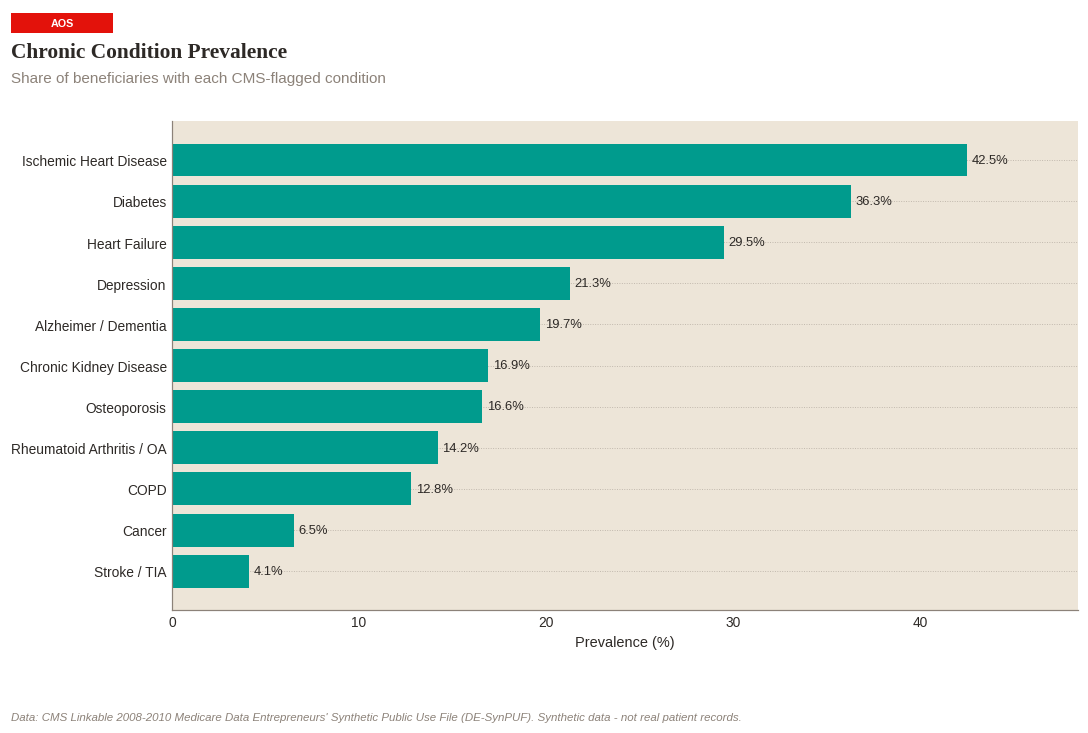

In [39]:
fig, ax = plt.subplots(figsize=(10, 6))
fig.subplots_adjust(top=0.99)
bars = ax.barh(df_chronic["condition"], df_chronic["prevalence_pct"], color=NATURE_TEAL)
bar_labels(ax, bars, fmt="{:.1f}%", horizontal=True)
adjust_axis(ax, xlabel="Prevalence (%)", ylabel="")
fig_title(fig, "Chronic Condition Prevalence",
          "Share of beneficiaries with each CMS-flagged condition",
          fonte=DATA_SOURCE_CITATION,
          top=0.90)
visual_identity(fig)
fig.savefig(FIGURES_DIR / "chronic_prevalence.png", dpi=150, bbox_inches="tight")
plt.show()

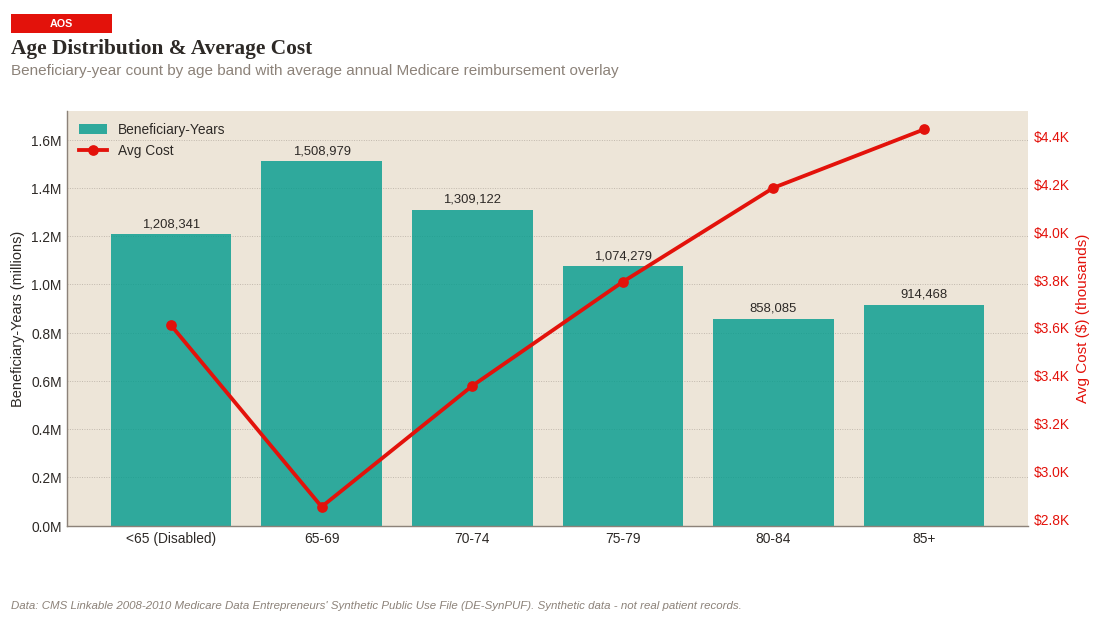

In [40]:
# 2c. Age distribution
# NOTE: The bene table has one row per beneficiary per benefit year (2008-2010),
# so counts here are beneficiary-years, not unique individuals.
df_age = con.execute("""
    SELECT age_band,
           COUNT(*) AS bene_years,
           ROUND(AVG(total_reimb), 2) AS avg_cost
    FROM bene
    GROUP BY age_band
    ORDER BY MIN(age)
""").fetchdf()

fig, ax1 = plt.subplots(figsize=(10, 5))
bars = ax1.bar(df_age["age_band"], df_age["bene_years"], color=NATURE_TEAL, alpha=0.8, label="Beneficiary-Years")
auto_scale_axis(ax1, axis="y", label="Beneficiary-Years")
bar_labels(ax1, bars, fmt="{:,.0f}", prefix="")

ax2 = ax1.twinx()
ax2.plot(df_age["age_band"], df_age["avg_cost"], color=ECON_RED, marker="o", linewidth=2.5, label="Avg Cost")
ax2.set_ylabel("Avg Annual Cost ($)", color=ECON_RED)
ax2.tick_params(axis="y", labelcolor=ECON_RED)
auto_scale_axis(ax2, axis="y", label="Avg Cost ($)", prefix="$")

adjust_axis(ax1, xlabel="", ylabel="")
fig_title(fig, "Age Distribution & Average Cost",
          "Beneficiary-year count by age band with average annual Medicare reimbursement overlay",
          fonte=DATA_SOURCE_CITATION,
          top=0.90)


# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", framealpha=0.9)

ax.grid(False)
ax2.grid(False)

ax2.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda v, pos=None: f"${v / 1e3:.1f}K")
)
ax2.yaxis.set_major_locator(mticker.MultipleLocator(200))

visual_identity(fig)
fig.savefig(FIGURES_DIR / "age_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


---

## S3 - Q1: Cost Concentration

> **Business question:** *What share of total Medicare spend is driven by the costliest 1%, 5%, and 10% of members?*

This is the first metric any health plan actuary produces. The "80/20 rule" (or closer to 50/5 in healthcare) tells medical directors where care management dollars will have the most impact.

In [8]:
# 3a. Cost concentration — Lorenz curve data─
df_lorenz = con.execute("""
    WITH ranked AS (
        SELECT total_reimb,
               ROW_NUMBER() OVER (ORDER BY total_reimb ASC) AS rn,
               COUNT(*) OVER () AS n
        FROM bene
        WHERE member_months > 0
    ),
    cumulative AS (
        SELECT rn,
               n,
               total_reimb,
               SUM(total_reimb) OVER (ORDER BY rn) AS cum_cost,
               SUM(total_reimb) OVER () AS total_cost
        FROM ranked
    )
    SELECT
        ROUND(100.0 * rn / n, 4)          AS pct_members,
        ROUND(100.0 * cum_cost / total_cost, 4) AS pct_cost
    FROM cumulative
    -- Sample ~1000 points for the curve + key percentiles
    WHERE rn % GREATEST(n / 1000, 1) = 0
       OR ROUND(100.0 * rn / n, 1) IN (90.0, 95.0, 99.0, 100.0)
    ORDER BY rn
""").fetchdf()

# Key percentile stats
df_pctiles = con.execute("""
    WITH ranked AS (
        SELECT total_reimb,
               PERCENT_RANK() OVER (ORDER BY total_reimb ASC) AS pctile
        FROM bene
        WHERE member_months > 0
    )
    SELECT
        ROUND(100.0 * SUM(CASE WHEN pctile >= 0.99 THEN total_reimb ELSE 0 END) / SUM(total_reimb), 1) AS top_1pct_share,
        ROUND(100.0 * SUM(CASE WHEN pctile >= 0.95 THEN total_reimb ELSE 0 END) / SUM(total_reimb), 1) AS top_5pct_share,
        ROUND(100.0 * SUM(CASE WHEN pctile >= 0.90 THEN total_reimb ELSE 0 END) / SUM(total_reimb), 1) AS top_10pct_share,
        ROUND(100.0 * SUM(CASE WHEN pctile >= 0.80 THEN total_reimb ELSE 0 END) / SUM(total_reimb), 1) AS top_20pct_share
    FROM ranked
""").fetchdf()

print("COST CONCENTRATION")
print("=" * 50)
print(f"  Top  1% of members drive {df_pctiles['top_1pct_share'].iloc[0]:.1f}% of total spend")
print(f"  Top  5% of members drive {df_pctiles['top_5pct_share'].iloc[0]:.1f}% of total spend")
print(f"  Top 10% of members drive {df_pctiles['top_10pct_share'].iloc[0]:.1f}% of total spend")
print(f"  Top 20% of members drive {df_pctiles['top_20pct_share'].iloc[0]:.1f}% of total spend")

COST CONCENTRATION
  Top  1% of members drive 16.0% of total spend
  Top  5% of members drive 43.1% of total spend
  Top 10% of members drive 59.8% of total spend
  Top 20% of members drive 76.4% of total spend


In [9]:
# 3a. Cost concentration — Lorenz curve data─
df_lorenz = con.execute("""
    WITH ranked AS (
        SELECT total_reimb,
               ROW_NUMBER() OVER (ORDER BY total_reimb ASC) AS rn,
               COUNT(*) OVER () AS n
        FROM bene
        WHERE member_months > 0
    ),
    cumulative AS (
        SELECT rn,
               n,
               total_reimb,
               SUM(total_reimb) OVER (ORDER BY rn) AS cum_cost,
               SUM(total_reimb) OVER () AS total_cost,
               -- '//' = integer division. A plain '/' returns DOUBLE in DuckDB,
               -- which made the modulo filter below match almost no rows
               GREATEST(n // 1000, 1) AS step
        FROM ranked
    )
    SELECT
        ROUND(100.0 * rn / n, 4)          AS pct_members,
        ROUND(100.0 * cum_cost / total_cost, 4) AS pct_cost
    FROM cumulative
    -- Sample ~1000 evenly spaced points; always keep the last row (100%, 100%)
    WHERE rn % step = 0
       OR rn = n
    ORDER BY rn
""").fetchdf()

# The SQL never emits the origin, so it is prepended explicitly:
# 0% of members must account for 0% of spend
df_lorenz = pd.concat(
    [pd.DataFrame({"pct_members": [0.0], "pct_cost": [0.0]}), df_lorenz],
    ignore_index=True
)

# Sanity check before plotting: the curve must span the full range and be monotonic
print(f"Lorenz points: {len(df_lorenz)} | x range: {df_lorenz['pct_members'].min():.2f} to {df_lorenz['pct_members'].max():.2f}")
print(f"x monotonic: {df_lorenz['pct_members'].is_monotonic_increasing} | y monotonic: {df_lorenz['pct_cost'].is_monotonic_increasing}")
print("")
# print("COST CONCENTRATION")
# print("=" * 50)
# # # print(f"  Top  1% of members drive {df_pctiles['top_1pct_share'].iloc[0]:.1f}% of total spend")
# print(f"  Top  5% of members drive {df_pctiles['top_5pct_share'].iloc[0]:.1f}% of total spend")
# print(f"  Top 10% of members drive {df_pctiles['top_10pct_share'].iloc[0]:.1f}% of total spend")
# print(f"  Top 20% of members drive {df_pctiles['top_20pct_share'].iloc[0]:.1f}% of total spend")

Lorenz points: 1002 | x range: 0.00 to 100.00
x monotonic: True | y monotonic: False



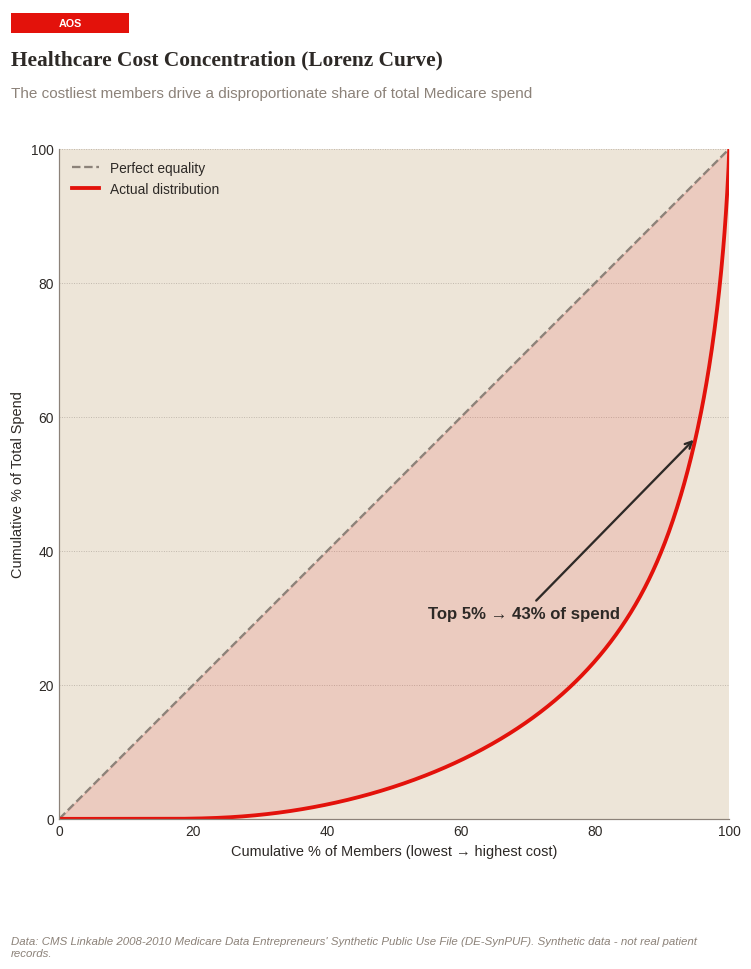

In [10]:
# 3b. Lorenz curve visualization
fig, ax = plt.subplots(figsize=(8, 8))

# Equality line
ax.plot([0, 100], [0, 100], "--", color=WARM_GREY, linewidth=1.5, label="Perfect equality")

# Lorenz curve
ax.plot(df_lorenz["pct_members"], df_lorenz["pct_cost"],
        color=ECON_RED, linewidth=2.5, label="Actual distribution")

# Fill the inequality area
ax.fill_between(df_lorenz["pct_members"], df_lorenz["pct_cost"],
                df_lorenz["pct_members"], alpha=0.12, color=ECON_RED)

# Annotate key percentiles
top5 = df_pctiles['top_5pct_share'].iloc[0]
ax.annotate(f"Top 5% → {top5:.0f}% of spend",
            xy=(95, 100 - top5), xytext=(55, 30),
            fontsize=11, fontweight="bold", color=CHARCOAL,
            arrowprops=dict(arrowstyle="->", color=CHARCOAL, lw=1.5))

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_aspect("equal")
adjust_axis(ax, xlabel="Cumulative % of Members (lowest → highest cost)",
            ylabel="Cumulative % of Total Spend")
ax.legend(loc="upper left", framealpha=0.9)

fig_title(fig, "Healthcare Cost Concentration (Lorenz Curve)",
          "The costliest members drive a disproportionate share of total Medicare spend",
          fonte=DATA_SOURCE_CITATION,
          top=0.90)
visual_identity(fig)
fig.savefig(FIGURES_DIR / "lorenz_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# Diagnostic: locate every step where the cumulative % of spend goes DOWN
df_lorenz["delta_cost"] = df_lorenz["pct_cost"].diff()
df_viol = df_lorenz[df_lorenz["delta_cost"] < 0]
print(f"Decreasing steps: {len(df_viol)} of {len(df_lorenz)} points")
print(f"Worst single decrease (pct points): {df_lorenz['delta_cost'].min():.6f}")
print(f"First violation at pct_members = {df_viol['pct_members'].min() if len(df_viol) else 'none'}")
print(f"Last violation at pct_members  = {df_viol['pct_members'].max() if len(df_viol) else 'none'}")
print(df_viol.head(10).to_string())

# Diagnostic: inspect the source column for NULLs, zeros and negative values
df_check = con.execute("""
    SELECT COUNT(*)                                             AS n_members,
           COUNT(*) FILTER (WHERE total_reimb IS NULL)          AS n_null,
           COUNT(*) FILTER (WHERE total_reimb = 0)              AS n_zero,
           COUNT(*) FILTER (WHERE total_reimb < 0)              AS n_negative,
           MIN(total_reimb)                                     AS min_reimb,
           SUM(CASE WHEN total_reimb < 0 THEN total_reimb ELSE 0 END) AS sum_negative,
           SUM(total_reimb)                                     AS sum_total
    FROM bene
    WHERE member_months > 0
""").fetchdf()
print(df_check.T)

Decreasing steps: 1 of 1002 points
Worst single decrease (pct points): -0.000400
First violation at pct_members = 0.1
Last violation at pct_members  = 0.1
   pct_members  pct_cost  delta_cost
1          0.1   -0.0004     -0.0004
                         0
n_members     6.315306e+06
n_null        0.000000e+00
n_zero        1.045093e+06
n_negative    3.250000e+02
min_reimb    -7.920000e+03
sum_negative -1.040400e+05
sum_total     2.456497e+10


---

## S4 - Q2: PMPM by Service Line

> **Business question:** *What is the Per Member Per Month cost by service line (inpatient, outpatient, professional, pharmacy), and how does it shift across years?*

PMPM is THE standard metric in health plan finance. Every board deck, every actuarial filing, every MLR calculation starts here.

In [44]:
# 4a. PMPM by service line
# Note: DE-SynPUF beneficiary file is annual. We approximate "year" from the
# file sample structure. Each beneficiary row has coverage months + costs.
# Total PMPM = total_reimb / member_months for members with >0 months.

df_pmpm = con.execute("""
    SELECT
        SUM(MEDREIMB_IP)  / NULLIF(SUM(member_months), 0) AS pmpm_inpatient,
        SUM(MEDREIMB_OP)  / NULLIF(SUM(member_months), 0) AS pmpm_outpatient,
        SUM(MEDREIMB_CAR) / NULLIF(SUM(member_months), 0) AS pmpm_carrier,
        SUM(total_reimb)  / NULLIF(SUM(member_months), 0) AS pmpm_total,
        SUM(member_months) AS total_member_months
    FROM bene
    WHERE member_months > 0
""").fetchdf()

# PDE costs from the PDE table (not on beneficiary summary)
df_pde_cost = con.execute("""
    SELECT ROUND(SUM(TOT_RX_CST_AMT), 2) AS total_rx_cost
    FROM pde
""").fetchdf()

total_mm = df_pmpm["total_member_months"].iloc[0]
pmpm_rx = df_pde_cost["total_rx_cost"].iloc[0] / total_mm

service_lines = {
    "Inpatient":    df_pmpm["pmpm_inpatient"].iloc[0],
    "Outpatient":   df_pmpm["pmpm_outpatient"].iloc[0],
    "Professional": df_pmpm["pmpm_carrier"].iloc[0],
    "Pharmacy":     pmpm_rx,
}

total_pmpm = sum(service_lines.values())

print("PMPM BY SERVICE LINE")
print("=" * 50)
for svc, val in service_lines.items():
    pct = 100.0 * val / total_pmpm
    print(f"  {svc:<15s}  ${val:>8,.2f}  ({pct:5.1f}%)")
print(f"  {'─'*42}")
print(f"  {'TOTAL':<15s}  ${total_pmpm:>8,.2f}")
print(f"\n  Member months: {total_mm:,.0f}")

PMPM BY SERVICE LINE
  Inpatient        $  171.59  ( 40.8%)
  Outpatient       $   55.70  ( 13.2%)
  Professional     $  102.32  ( 24.3%)
  Pharmacy         $   91.42  ( 21.7%)
  ──────────────────────────────────────────
  TOTAL            $  421.03

  Member months: 74,527,860


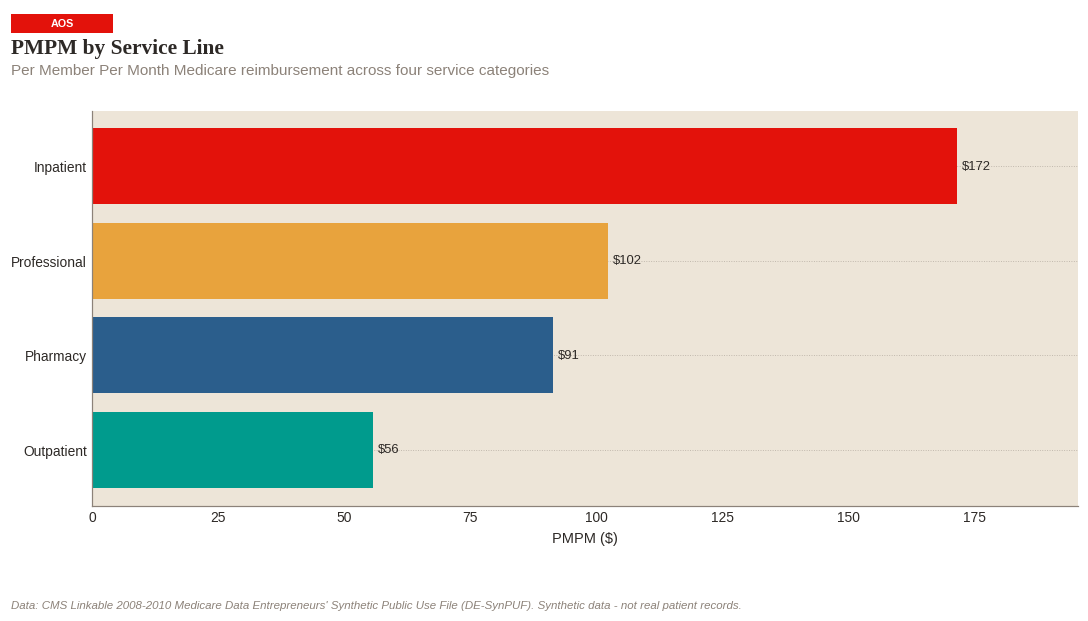

In [45]:
# 4b. PMPM waterfall chart
df_svc = pd.DataFrame({
    "Service Line": list(service_lines.keys()),
    "PMPM":         list(service_lines.values()),
})
df_svc = df_svc.sort_values("PMPM", ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
colors = [NATURE_TEAL, DEEP_BLUE, AMBER, ECON_RED]
bars = ax.barh(df_svc["Service Line"], df_svc["PMPM"],
               color=colors[:len(df_svc)])
bar_labels(ax, bars, fmt="${:,.0f}", horizontal=True)

adjust_axis(ax, xlabel="PMPM ($)", ylabel="")
fig_title(fig, "PMPM by Service Line",
          "Per Member Per Month Medicare reimbursement across four service categories",
          fonte=DATA_SOURCE_CITATION,
          top=0.90)
visual_identity(fig)
fig.savefig(FIGURES_DIR / "pmpm_service_line.png", dpi=150, bbox_inches="tight")
plt.show()

In [46]:
# 4c. Year-over-year PMPM trending (2008-2010)─
# With bene_year extracted from filenames, we can track how PMPM shifts
# across the three benefit years in the DE-SynPUF dataset.

df_yoy = con.execute("""
    SELECT
        bene_year,
        COUNT(*) AS members,
        SUM(member_months) AS total_mm,
        ROUND(SUM(MEDREIMB_IP)  / NULLIF(SUM(member_months), 0), 2) AS pmpm_inpatient,
        ROUND(SUM(MEDREIMB_OP)  / NULLIF(SUM(member_months), 0), 2) AS pmpm_outpatient,
        ROUND(SUM(MEDREIMB_CAR) / NULLIF(SUM(member_months), 0), 2) AS pmpm_carrier,
        ROUND(
            (COALESCE(SUM(MEDREIMB_IP), 0) + COALESCE(SUM(MEDREIMB_OP), 0) + COALESCE(SUM(MEDREIMB_CAR), 0))
            / NULLIF(SUM(member_months), 0),
        2) AS pmpm_medical
    FROM bene
    WHERE member_months > 0
    GROUP BY bene_year
    ORDER BY bene_year
""").fetchdf()

# Add pharmacy PMPM by year (from PDE claims via service date).
# SRVC_DT is stored as a YYYYMMDD integer (BIGINT) in DE-SynPUF CSVs,
# so we parse it to DATE first, then extract the year.
df_rx_yoy = con.execute("""
    SELECT
        EXTRACT(YEAR FROM
            COALESCE(
                TRY_CAST(SRVC_DT AS DATE),
                TRY_STRPTIME(CAST(SRVC_DT AS VARCHAR), '%Y%m%d')::DATE
            )
        ) AS rx_year,
        ROUND(SUM(TOT_RX_CST_AMT), 2) AS total_rx_cost
    FROM pde
    GROUP BY rx_year
    ORDER BY rx_year
""").fetchdf()

# Merge pharmacy into the YoY table by matching year
df_yoy = df_yoy.merge(
    df_rx_yoy.rename(columns={"rx_year": "bene_year"}),
    on="bene_year",
    how="left"
)
df_yoy["pmpm_pharmacy"] = df_yoy["total_rx_cost"] / df_yoy["total_mm"]
df_yoy["pmpm_total"]    = df_yoy["pmpm_medical"] + df_yoy["pmpm_pharmacy"]

print("YEAR-OVER-YEAR PMPM TRENDING")
print("=" * 80)
print(f"  {'Year':<6s} {'Members':>10s} {'Member Mo':>12s} "
      f"{'IP PMPM':>10s} {'OP PMPM':>10s} {'Prof PMPM':>10s} "
      f"{'Rx PMPM':>10s} {'Total':>10s}")
print(f"  {'─'*76}")
for _, row in df_yoy.iterrows():
    print(f"  {int(row['bene_year']):<6d} {row['members']:>10,.0f} {row['total_mm']:>12,.0f} "
          f"${row['pmpm_inpatient']:>9,.2f} ${row['pmpm_outpatient']:>9,.2f} "
          f"${row['pmpm_carrier']:>9,.2f} ${row['pmpm_pharmacy']:>9,.2f} "
          f"${row['pmpm_total']:>9,.2f}")

YEAR-OVER-YEAR PMPM TRENDING
  Year      Members    Member Mo    IP PMPM    OP PMPM  Prof PMPM    Rx PMPM      Total
  ────────────────────────────────────────────────────────────────────────────
  2008    2,101,719   24,425,115 $   205.55 $    58.48 $   108.91 $   100.29 $   473.22
  2009    2,131,175   25,450,254 $   195.15 $    68.62 $   120.09 $   105.05 $   488.91
  2010    2,082,412   24,652,491 $   113.62 $    39.60 $    77.46 $    68.55 $   299.23


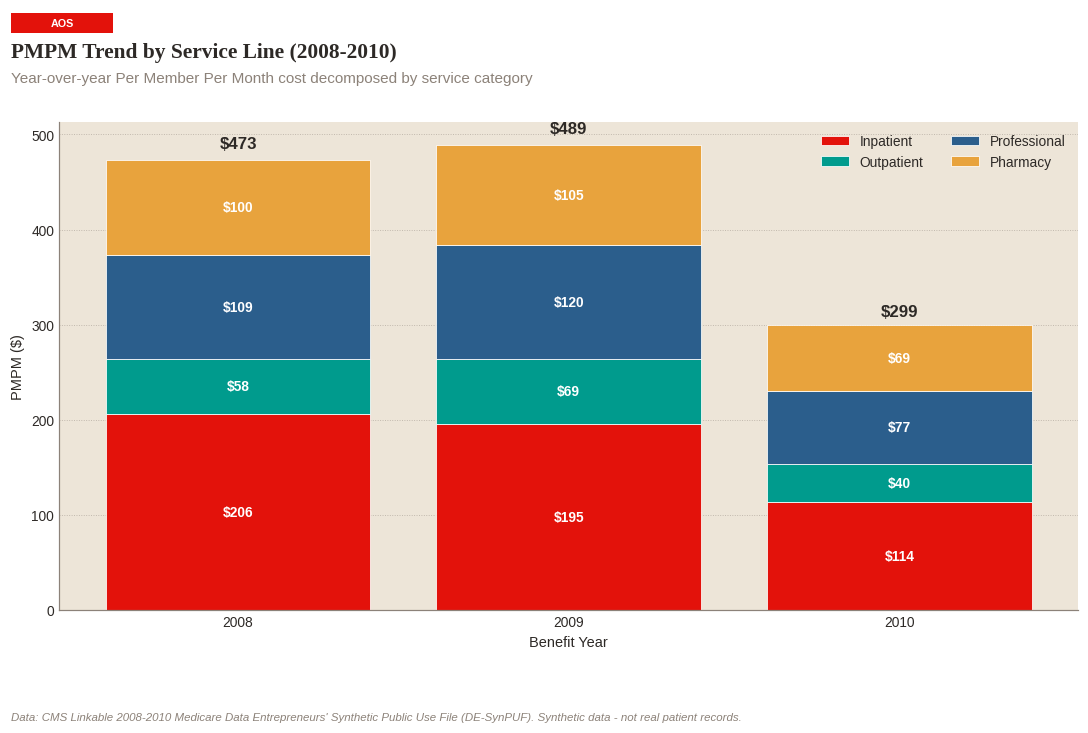

In [47]:
# 4d. YoY PMPM stacked bar chart─
# Stacked bars show the service-line mix shifting across years, which is
# the exact view a VP of Medical Economics uses to spot trend breaks.
# FIX: Legend moved to upper right with ncol=4 to avoid collision with
# the total PMPM annotations above each bar.

years = df_yoy["bene_year"].astype(int).astype(str)
svc_cols   = ["pmpm_inpatient", "pmpm_outpatient", "pmpm_carrier", "pmpm_pharmacy"]
svc_labels = ["Inpatient", "Outpatient", "Professional", "Pharmacy"]
svc_colors = [ECON_RED, NATURE_TEAL, DEEP_BLUE, AMBER]

fig, ax = plt.subplots(figsize=(10, 6))

bottom = np.zeros(len(df_yoy))
for col, label, color in zip(svc_cols, svc_labels, svc_colors):
    vals = df_yoy[col].values
    ax.bar(years, vals, bottom=bottom, color=color, label=label, edgecolor="white", linewidth=0.5)
    # Label each segment at its midpoint
    for i, v in enumerate(vals):
        if v > 30:  # skip labels in thin segments to avoid overlap
            ax.text(i, bottom[i] + v / 2, f"${v:,.0f}",
                    ha="center", va="center", fontsize=9, fontweight="bold", color=WHITE)
    bottom += vals

# Total PMPM annotation on top of each bar
for i, total in enumerate(df_yoy["pmpm_total"].values):
    ax.text(i, total + total * 0.02, f"${total:,.0f}",
            ha="center", va="bottom", fontsize=11, fontweight="bold", color=CHARCOAL)

adjust_axis(ax, xlabel="Benefit Year", ylabel="PMPM ($)")
ax.legend(loc="upper right", framealpha=0.9, ncol=2, fontsize=9)

fig_title(fig, "PMPM Trend by Service Line (2008-2010)",
          "Year-over-year Per Member Per Month cost decomposed by service category",
          fonte=DATA_SOURCE_CITATION,
          top=0.90)
visual_identity(fig)
fig.savefig(FIGURES_DIR / "pmpm_yoy_trend.png", dpi=150, bbox_inches="tight")
plt.show()


> **Data caveat:** The sharp PMPM decline in 2010 (-39% vs. 2009) is a known artifact of DE-SynPUF's
> synthetic data generation process. CMS applied cost suppression and noise injection that compresses
> reimbursement distributions unevenly across benefit years. The 2010 drop does not reflect an actual
> Medicare cost trend. Year-over-year comparisons in DE-SynPUF should be interpreted as illustrative
> of the *method* (service-line decomposition, PMPM trending), not as evidence of real-world shifts.
> In production, this analysis would run on adjudicated claims from the plan's data warehouse.


---

## S5 - Q3: Chronic Condition Cost Layering

> **Business question:** *How does the incremental cost grow as members accumulate multiple chronic conditions? Which combinations are the costliest?*

This analysis directly informs care management program design. A plan that can identify members at 2 conditions and intervene before they reach 4+ saves significant PMPM.

In [48]:
# 5a. PMPM by chronic condition count─
# FIX: The original GROUP BY ALL kept individual rows for chronic_count
# 6, 7, 8, 9, 10, 11 all labeled "6+", creating six duplicate x-axis
# labels.  Now we group by the CASE expression so 6+ is a true aggregate.
df_cc = con.execute("""
    SELECT
        CASE WHEN chronic_count >= 6 THEN '6+' ELSE chronic_count::VARCHAR END AS conditions,
        MIN(chronic_count) AS sort_key,
        COUNT(*) AS members,
        ROUND(AVG(total_reimb), 2) AS avg_annual_cost,
        ROUND(SUM(total_reimb) / NULLIF(SUM(member_months), 0), 2) AS pmpm
    FROM bene
    WHERE member_months > 0
    GROUP BY CASE WHEN chronic_count >= 6 THEN '6+' ELSE chronic_count::VARCHAR END
    ORDER BY MIN(chronic_count)
""").fetchdf()

# Incremental PMPM
df_cc["incremental_pmpm"] = df_cc["pmpm"].diff().fillna(df_cc["pmpm"])

print("PMPM BY CHRONIC CONDITION COUNT")
print("=" * 70)
print(f"  {'Conditions':<12s} {'Members':>10s} {'PMPM':>10s} {'Δ PMPM':>10s} {'Avg Annual':>12s}")
print(f"  {'─'*60}")
for _, r in df_cc.iterrows():
    print(f"  {r['conditions']:<12s} {r['members']:>10,} ${r['pmpm']:>9,.2f} "
          f"+${r['incremental_pmpm']:>8,.2f} ${r['avg_annual_cost']:>11,.2f}")


PMPM BY CHRONIC CONDITION COUNT
  Conditions      Members       PMPM     Δ PMPM   Avg Annual
  ────────────────────────────────────────────────────────────
  0             2,000,907 $    28.38 +$   28.38 $     329.46
  1               869,056 $   135.34 +$  106.96 $   1,595.05
  2               816,142 $   222.22 +$   86.88 $   2,636.02
  3               736,540 $   322.33 +$  100.11 $   3,837.15
  4               623,769 $   450.91 +$  128.58 $   5,379.60
  5               488,728 $   618.72 +$  167.81 $   7,390.94
  6+              780,164 $ 1,133.52 +$  514.80 $  13,553.81


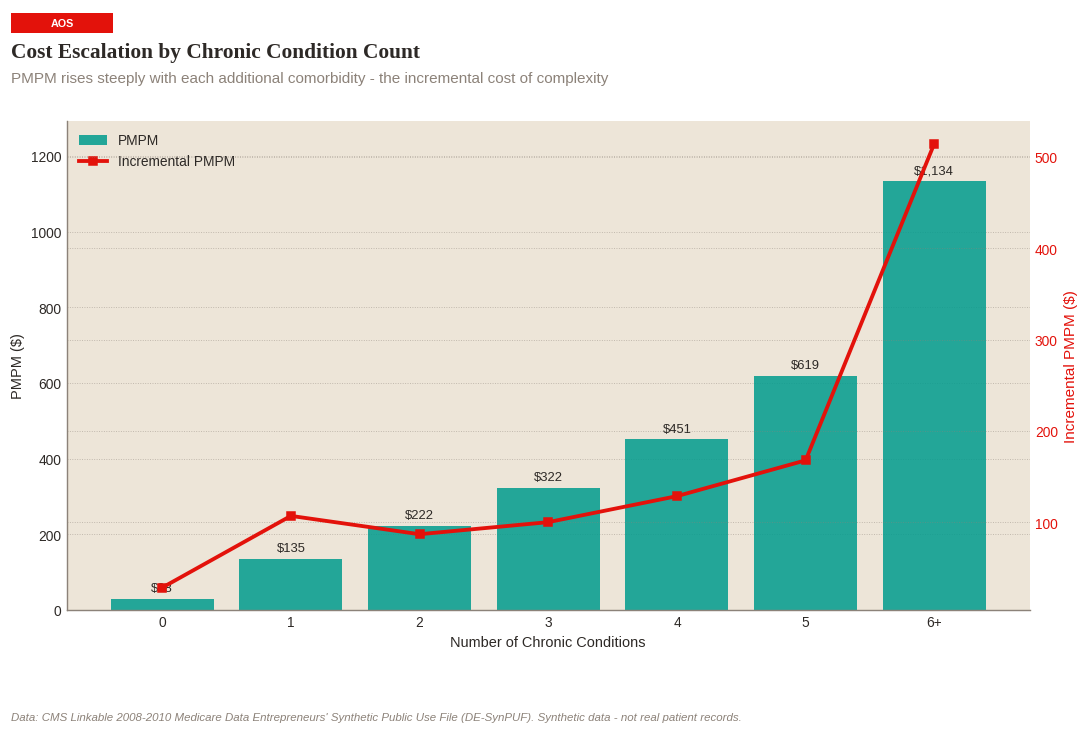

In [49]:
# 5b. Chronic condition layering chart
fig, ax1 = plt.subplots(figsize=(10, 6))

x = range(len(df_cc))
bars = ax1.bar(x, df_cc["pmpm"], color=NATURE_TEAL, alpha=0.85, label="PMPM", zorder=2)
bar_labels(ax1, bars, fmt="${:,.0f}")
ax1.set_xticks(x)
ax1.set_xticklabels(df_cc["conditions"])

# Overlay incremental PMPM as line
ax2 = ax1.twinx()
ax2.plot(x, df_cc["incremental_pmpm"], color=ECON_RED, marker="s",
         linewidth=2.5, markersize=5, label="Incremental PMPM", zorder=3)
ax2.set_ylabel("Incremental PMPM ($)", color=ECON_RED)
ax2.tick_params(axis="y", labelcolor=ECON_RED)

adjust_axis(ax1, xlabel="Number of Chronic Conditions", ylabel="PMPM ($)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", framealpha=0.9)

fig_title(fig, "Cost Escalation by Chronic Condition Count",
          "PMPM rises steeply with each additional comorbidity - the incremental cost of complexity",
          fonte=DATA_SOURCE_CITATION,
          top=0.90)
visual_identity(fig)
fig.savefig(FIGURES_DIR / "chronic_layering.png", dpi=150, bbox_inches="tight")
plt.show()

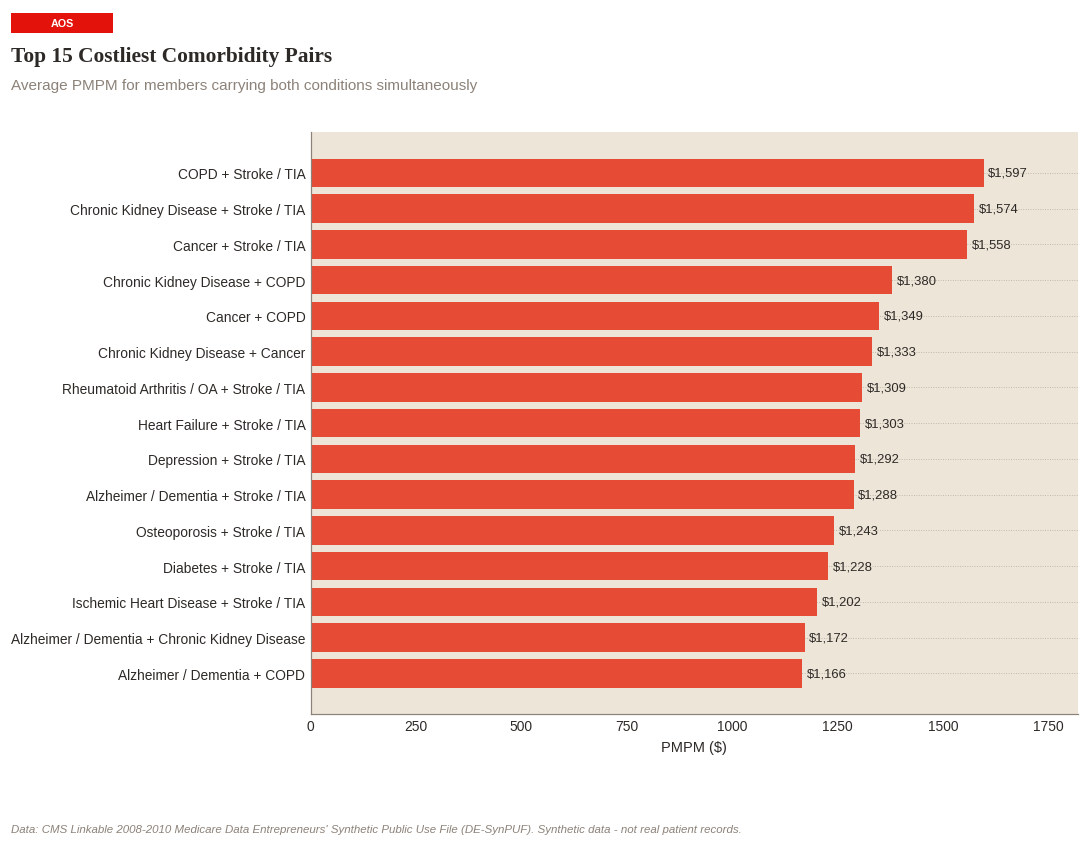

In [50]:
# 5c. Top comorbidity pairs by cost─
# Build all 2-condition combinations and their average cost
from itertools import combinations

pairs_sql = []
for c1, c2 in combinations(CHRONIC_CONDITION_COLS, 2):
    l1 = CHRONIC_CONDITION_LABELS[c1]
    l2 = CHRONIC_CONDITION_LABELS[c2]
    pairs_sql.append(f"""
        SELECT '{l1} + {l2}' AS pair,
               COUNT(*) AS members,
               ROUND(AVG(total_reimb), 2) AS avg_cost,
               ROUND(SUM(total_reimb) / NULLIF(SUM(member_months), 0), 2) AS pmpm
        FROM bene
        WHERE {c1} = 1 AND {c2} = 1 AND member_months > 0
    """)

df_pairs = con.execute(" UNION ALL ".join(pairs_sql)).fetchdf()
df_pairs = df_pairs.sort_values("pmpm", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(range(len(df_pairs)), df_pairs["pmpm"].values, color=NATURE_CORAL)
ax.set_yticks(range(len(df_pairs)))
ax.set_yticklabels(df_pairs["pair"].values, fontsize=9)
ax.invert_yaxis()
bar_labels(ax, bars, fmt="${:,.0f}", horizontal=True)

adjust_axis(ax, xlabel="PMPM ($)", ylabel="")
fig_title(fig, "Top 15 Costliest Comorbidity Pairs",
          "Average PMPM for members carrying both conditions simultaneously",
          fonte=DATA_SOURCE_CITATION,
          top=0.90)
visual_identity(fig)
fig.savefig(FIGURES_DIR / "comorbidity_pairs.png", dpi=150, bbox_inches="tight")
plt.show()

---

## S6 - Q4: Avoidable Utilization - 30-Day Readmissions

> **Business question:** *What is the 30-day all-cause readmission rate? Which DRGs drive the most readmissions, and what is the estimated avoidable spend?*

CMS penalizes hospitals (and by extension, MA plans) for excess readmissions under HRRP. Identifying high-readmission DRGs is the first step toward targeted transitional care programs.

In [51]:
# 6a. Identify 30-day readmissions from inpatient claims
# CLM_FROM_DT and CLM_THRU_DT are stored as YYYYMMDD integers (BIGINT)
# in DE-SynPUF CSVs. We parse them to DATE before any date arithmetic.
df_readmit = con.execute("""
    WITH admissions AS (
        SELECT
            DESYNPUF_ID,
            CLM_ID,
            COALESCE(
                TRY_CAST(CLM_FROM_DT AS DATE),
                TRY_STRPTIME(CAST(CLM_FROM_DT AS VARCHAR), '%Y%m%d')::DATE
            ) AS admit_dt,
            COALESCE(
                TRY_CAST(CLM_THRU_DT AS DATE),
                TRY_STRPTIME(CAST(CLM_THRU_DT AS VARCHAR), '%Y%m%d')::DATE
            ) AS discharge_dt,
            CLM_PMT_AMT,
            CLM_DRG_CD,
            LEAD(
                COALESCE(
                    TRY_CAST(CLM_FROM_DT AS DATE),
                    TRY_STRPTIME(CAST(CLM_FROM_DT AS VARCHAR), '%Y%m%d')::DATE
                )
            ) OVER (
                PARTITION BY DESYNPUF_ID
                ORDER BY
                    COALESCE(
                        TRY_CAST(CLM_FROM_DT AS DATE),
                        TRY_STRPTIME(CAST(CLM_FROM_DT AS VARCHAR), '%Y%m%d')::DATE
                    ),
                    CLM_ID
            ) AS next_admit_dt
        FROM inpatient
    ),
    flagged AS (
        SELECT *,
            DATEDIFF('day', discharge_dt, next_admit_dt) AS days_to_readmit,
            CASE
                WHEN DATEDIFF('day', discharge_dt, next_admit_dt) BETWEEN 0 AND 30
                THEN 1 ELSE 0
            END AS is_readmit_index
        FROM admissions
    )
    SELECT
        COUNT(*)                                          AS total_admissions,
        SUM(is_readmit_index)                             AS readmit_index_stays,
        ROUND(100.0 * SUM(is_readmit_index) / COUNT(*), 2) AS readmit_rate_pct,
        ROUND(AVG(CASE WHEN is_readmit_index = 1 THEN days_to_readmit END), 1) AS avg_days_to_readmit,
        ROUND(SUM(CASE WHEN is_readmit_index = 1 THEN CLM_PMT_AMT ELSE 0 END), 2) AS total_readmit_cost
    FROM flagged
""").fetchdf()

r = df_readmit.iloc[0]
print("30-DAY ALL-CAUSE READMISSION SUMMARY")
print("=" * 55)
print(f"  Total inpatient stays:     {r['total_admissions']:>12,}")
print(f"  Index stays w/ readmission:{r['readmit_index_stays']:>12,}")
print(f"  Readmission rate:          {r['readmit_rate_pct']:>11.1f}%")
print(f"  Avg days to readmission:   {r['avg_days_to_readmit']:>11.1f}")
print(f"  Total readmission cost:    ${r['total_readmit_cost']:>11,.0f}")

30-DAY ALL-CAUSE READMISSION SUMMARY
  Total inpatient stays:      1,332,822.0
  Index stays w/ readmission:   133,458.0
  Readmission rate:                 10.0%
  Avg days to readmission:          13.4
  Total readmission cost:    $1,285,734,830


In [52]:
# MS-DRG description lookup
# CMS MS-DRG v27/v28 descriptions for the DRGs appearing in DE-SynPUF.
# In production, this would be a JOIN to the CMS ICD-10/MS-DRG crosswalk;
# here we embed the relevant subset to keep the notebook self-contained.
MS_DRG_LABELS = {
    "177": "Respiratory infections w/o CC/MCC",
    "178": "Respiratory infections w/ MCC",
    "182": "Respiratory neoplasms w/ MCC",
    "189": "Pulmonary edema & resp failure",
    "190": "COPD w/ MCC",
    "191": "COPD w/ CC",
    "192": "COPD w/o CC/MCC",
    "193": "Simple pneumonia & pleurisy w/ MCC",
    "194": "Simple pneumonia & pleurisy w/ CC",
    "195": "Simple pneumonia & pleurisy w/o CC/MCC",
    "198": "Interstitial lung disease w/ MCC",
    "200": "Pneumothorax w/ MCC",
    "201": "Pneumothorax w/o MCC",
    "280": "Acute MI, discharged alive w/ MCC",
    "281": "Acute MI, discharged alive w/ CC",
    "291": "Heart failure & shock w/ MCC",
    "292": "Heart failure & shock w/ CC",
    "293": "Heart failure & shock w/o CC/MCC",
    "300": "Peripheral vascular disorders w/ MCC",
    "301": "Peripheral vascular disorders w/ CC",
    "378": "GI hemorrhage w/ MCC",
    "392": "Esophagitis, gastroent & misc digestive w/ MCC",
    "470": "Major hip/knee joint replacement",
    "473": "Cervical spinal fusion w/o CC/MCC",
    "480": "Hip & femur procedures w/ MCC",
    "481": "Hip & femur procedures w/ CC",
    "603": "Cellulitis w/o MCC",
    "682": "Renal failure w/ MCC",
    "683": "Renal failure w/ CC",
    "684": "Renal failure w/o CC/MCC",
    "690": "Kidney & urinary tract infections w/ MCC",
    "871": "Septicemia or severe sepsis w/o MV >96 hrs w/ MCC",
    "872": "Septicemia or severe sepsis w/o MV >96 hrs w/o MCC",
    "853": "Infectious & parasitic diseases w/ OR proc w/ MCC",
    "855": "Infectious & parasitic diseases w/o OR proc w/ MCC",
    "858": "Postoperative & post-traumatic infections w/ MCC",
    "862": "Postoperative & post-traumatic infections w/ CC",
    "864": "Fever",
    "865": "Viral illness w/ MCC",
    "866": "Viral illness w/o MCC",
    "868": "Other infectious & parasitic diseases diagnoses w/ MCC",
    "869": "Other infectious & parasitic diseases diagnoses w/ CC",
    "870": "Septicemia or severe sepsis w/ MV >96 hrs",
    "880": "Acute adjustment reaction & psychosocial dysfunction",
    "881": "Depressive neuroses",
    "882": "Neuroses except depressive",
    "883": "Disorders of personality & impulse control",
    "884": "Organic disturbances & intellectual disability",
    "885": "Psychoses",
    "886": "Behavioral & developmental disorders",
    "897": "Alcohol/drug abuse or dependence w/o rehab w/o MCC",
    "917": "Poisoning & toxic effects of drugs w/ MCC",
    "918": "Poisoning & toxic effects of drugs w/o MCC",
    "939": "OR proc w/ diagnoses of other contact w/ health services w/ MCC",
    "940": "OR proc w/ diagnoses of other contact w/ health services w/ CC",
    "941": "OR proc w/ diagnoses of other contact w/ health services w/o CC/MCC",
    "945": "Rehabilitation w/ CC/MCC",
    "946": "Rehabilitation w/o CC/MCC",
    "947": "Signs & symptoms w/ MCC",
    "948": "Signs & symptoms w/o MCC",
    "949": "Aftercare w/ CC/MCC",
    "950": "Aftercare w/o CC/MCC",
    "951": "Other factors influencing health status",
}

def drg_label(code):
    """Return 'DRG {code} - {description}' or just 'DRG {code}' if unmapped."""
    code_str = str(code).strip()
    desc = MS_DRG_LABELS.get(code_str)
    if desc:
        # Truncate long descriptions for chart readability
        if len(desc) > 40:
            desc = desc[:37] + "..."
        return f"DRG {code_str} - {desc}"
    return f"DRG {code_str}"

print(f"✓ MS-DRG lookup loaded: {len(MS_DRG_LABELS)} descriptions")


✓ MS-DRG lookup loaded: 63 descriptions


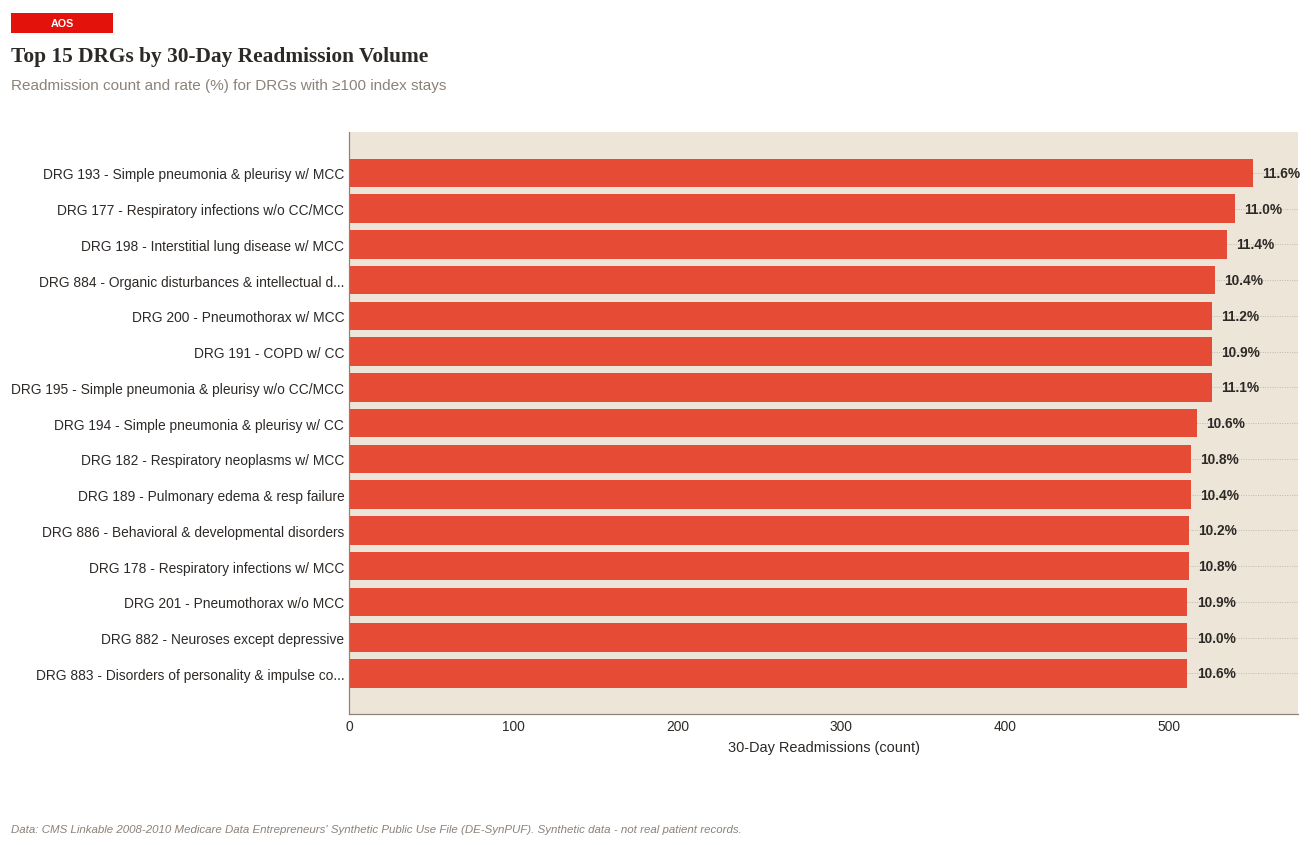

In [53]:
# 6b. Top DRGs by readmission volume
# Same BIGINT-to-DATE parsing as cell 6a for CLM_FROM_DT and CLM_THRU_DT.
df_drg_readmit = con.execute("""
    WITH admissions AS (
        SELECT
            DESYNPUF_ID, CLM_ID, CLM_DRG_CD, CLM_PMT_AMT,
            COALESCE(
                TRY_CAST(CLM_FROM_DT AS DATE),
                TRY_STRPTIME(CAST(CLM_FROM_DT AS VARCHAR), '%Y%m%d')::DATE
            ) AS admit_dt,
            COALESCE(
                TRY_CAST(CLM_THRU_DT AS DATE),
                TRY_STRPTIME(CAST(CLM_THRU_DT AS VARCHAR), '%Y%m%d')::DATE
            ) AS discharge_dt,
            LEAD(
                COALESCE(
                    TRY_CAST(CLM_FROM_DT AS DATE),
                    TRY_STRPTIME(CAST(CLM_FROM_DT AS VARCHAR), '%Y%m%d')::DATE
                )
            ) OVER (
                PARTITION BY DESYNPUF_ID
                ORDER BY
                    COALESCE(
                        TRY_CAST(CLM_FROM_DT AS DATE),
                        TRY_STRPTIME(CAST(CLM_FROM_DT AS VARCHAR), '%Y%m%d')::DATE
                    ),
                    CLM_ID
            ) AS next_admit_dt
        FROM inpatient
        WHERE CLM_DRG_CD IS NOT NULL AND CLM_DRG_CD != ''
    ),
    flagged AS (
        SELECT *,
            CASE WHEN DATEDIFF('day', discharge_dt, next_admit_dt) BETWEEN 0 AND 30
                 THEN 1 ELSE 0 END AS is_readmit
        FROM admissions
    )
    SELECT
        CLM_DRG_CD AS drg,
        COUNT(*) AS total_stays,
        SUM(is_readmit) AS readmissions,
        ROUND(100.0 * SUM(is_readmit) / COUNT(*), 1) AS readmit_rate,
        ROUND(SUM(CASE WHEN is_readmit = 1 THEN CLM_PMT_AMT ELSE 0 END), 0) AS readmit_cost
    FROM flagged
    GROUP BY CLM_DRG_CD
    HAVING COUNT(*) >= 100  -- minimum volume for reliability
    ORDER BY readmissions DESC
    LIMIT 15
""").fetchdf()

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(range(len(df_drg_readmit)),
               df_drg_readmit["readmissions"].values,
               color=NATURE_CORAL)
ax.set_yticks(range(len(df_drg_readmit)))
ax.set_yticklabels([drg_label(d) for d in df_drg_readmit["drg"].values], fontsize=8)
ax.invert_yaxis()

# Add readmission rate as text
for i, (_, row) in enumerate(df_drg_readmit.iterrows()):
    ax.text(row["readmissions"] + ax.get_xlim()[1] * 0.01, i,
            f'{row["readmit_rate"]:.1f}%', va="center", fontsize=9,
            color=CHARCOAL, fontweight="bold")

adjust_axis(ax, xlabel="30-Day Readmissions (count)", ylabel="")
fig_title(fig, "Top 15 DRGs by 30-Day Readmission Volume",
          "Readmission count and rate (%) for DRGs with \u2265100 index stays",
          fonte=DATA_SOURCE_CITATION,
          top=0.90)
visual_identity(fig)
fig.savefig(FIGURES_DIR / "drg_readmissions.png", dpi=150, bbox_inches="tight")
plt.show()


> **Data caveat:** The near-uniform readmission rates across DRGs (10-11.6%) are a DE-SynPUF artifact.
> CMS's synthetic data generation flattened utilization variance: in real Medicare claims, heart failure
> readmission rates typically exceed 20% while orthopedic DRGs run below 5%. The analysis demonstrates
> the correct methodology (index stay identification, LEAD-based pairing, DRG stratification), but the
> rate variation that would drive clinical prioritization is absent from this synthetic dataset.


---

## S7 - Q5: Age-Sex Cost Curves

> **Business question:** *How does PMPM vary by age band and sex? Where are the cost inflection points?*

Standard actuarial profiling. These curves feed directly into risk adjustment, premium rating, and reserve setting at every health plan.

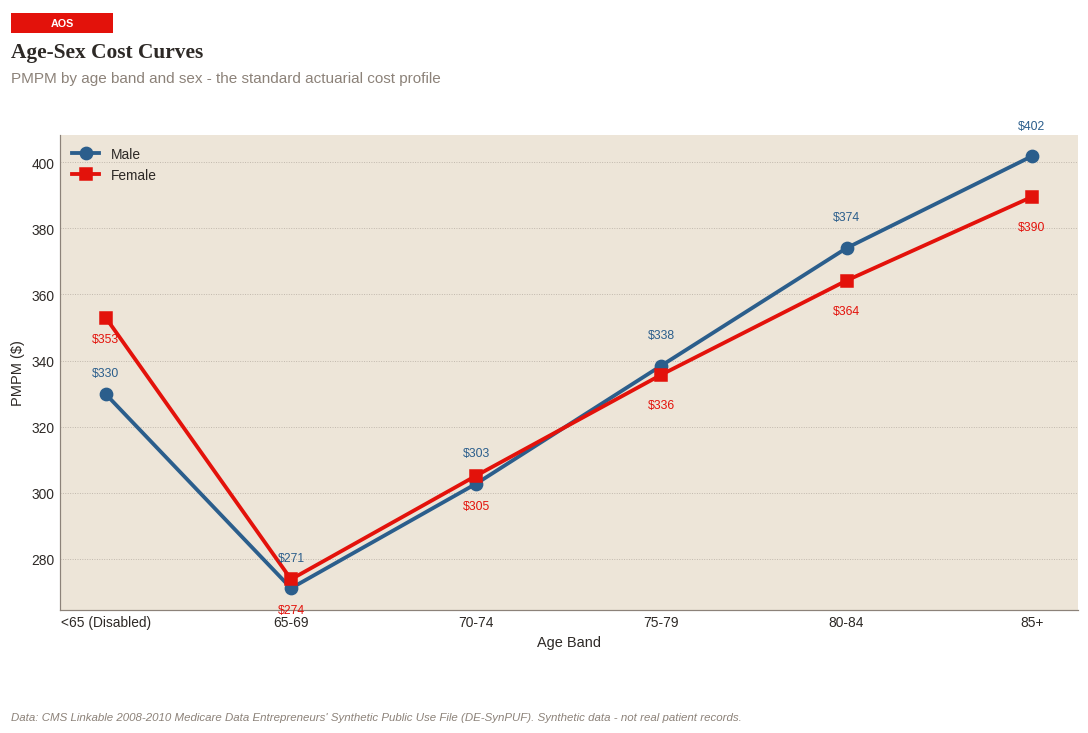

In [54]:
# 7a. PMPM by age band x sex
df_agesex = con.execute("""
    SELECT
        age_band,
        sex,
        COUNT(*) AS members,
        ROUND(SUM(total_reimb) / NULLIF(SUM(member_months), 0), 2) AS pmpm,
        MIN(age) AS sort_key
    FROM bene
    WHERE member_months > 0 AND sex IN ('Male', 'Female')
    GROUP BY age_band, sex
    ORDER BY MIN(age), sex
""").fetchdf()

# Pivot for plotting
df_m = df_agesex[df_agesex["sex"] == "Male"].sort_values("sort_key")
df_f = df_agesex[df_agesex["sex"] == "Female"].sort_values("sort_key")

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(df_m["age_band"], df_m["pmpm"], color=DEEP_BLUE,
        marker="o", linewidth=2.5, markersize=8, label="Male")
ax.plot(df_f["age_band"], df_f["pmpm"], color=ECON_RED,
        marker="s", linewidth=2.5, markersize=8, label="Female")

# Annotate values with dynamic offsets to avoid overlap when lines converge
pmpm_by_band = {}
for _, row in df_m.iterrows():
    pmpm_by_band.setdefault(row["age_band"], {})["Male"] = row["pmpm"]
for _, row in df_f.iterrows():
    pmpm_by_band.setdefault(row["age_band"], {})["Female"] = row["pmpm"]

for _, row in df_m.iterrows():
    gap = abs(pmpm_by_band[row["age_band"]].get("Male", 0)
              - pmpm_by_band[row["age_band"]].get("Female", 0))
    y_off = 18 if gap < 15 else 12
    ax.annotate(f"${row['pmpm']:,.0f}", (row["age_band"], row["pmpm"]),
                textcoords="offset points", xytext=(0, y_off),
                fontsize=8, ha="center", color=DEEP_BLUE)
for _, row in df_f.iterrows():
    gap = abs(pmpm_by_band[row["age_band"]].get("Male", 0)
              - pmpm_by_band[row["age_band"]].get("Female", 0))
    y_off = -22 if gap < 15 else -16
    ax.annotate(f"${row['pmpm']:,.0f}", (row["age_band"], row["pmpm"]),
                textcoords="offset points", xytext=(0, y_off),
                fontsize=8, ha="center", color=ECON_RED)

adjust_axis(ax, xlabel="Age Band", ylabel="PMPM ($)")
ax.legend(framealpha=0.9)

fig_title(fig, "Age-Sex Cost Curves",
          "PMPM by age band and sex - the standard actuarial cost profile",
          fonte=DATA_SOURCE_CITATION,
          top=0.90)
visual_identity(fig)
fig.savefig(FIGURES_DIR / "age_sex_curves.png", dpi=150, bbox_inches="tight")

plt.show()

---

## S8 - Q6: Top Cost Drivers

> **Business question:** *What are the top DRGs, HCPCS codes, and drug categories by total Medicare spend?*

This is the operational companion to the PMPM analysis. Where PMPM says how much, this section says what specifically. Network contracting teams use DRG rankings to negotiate hospital rates; pharmacy directors use drug rankings to manage formulary.

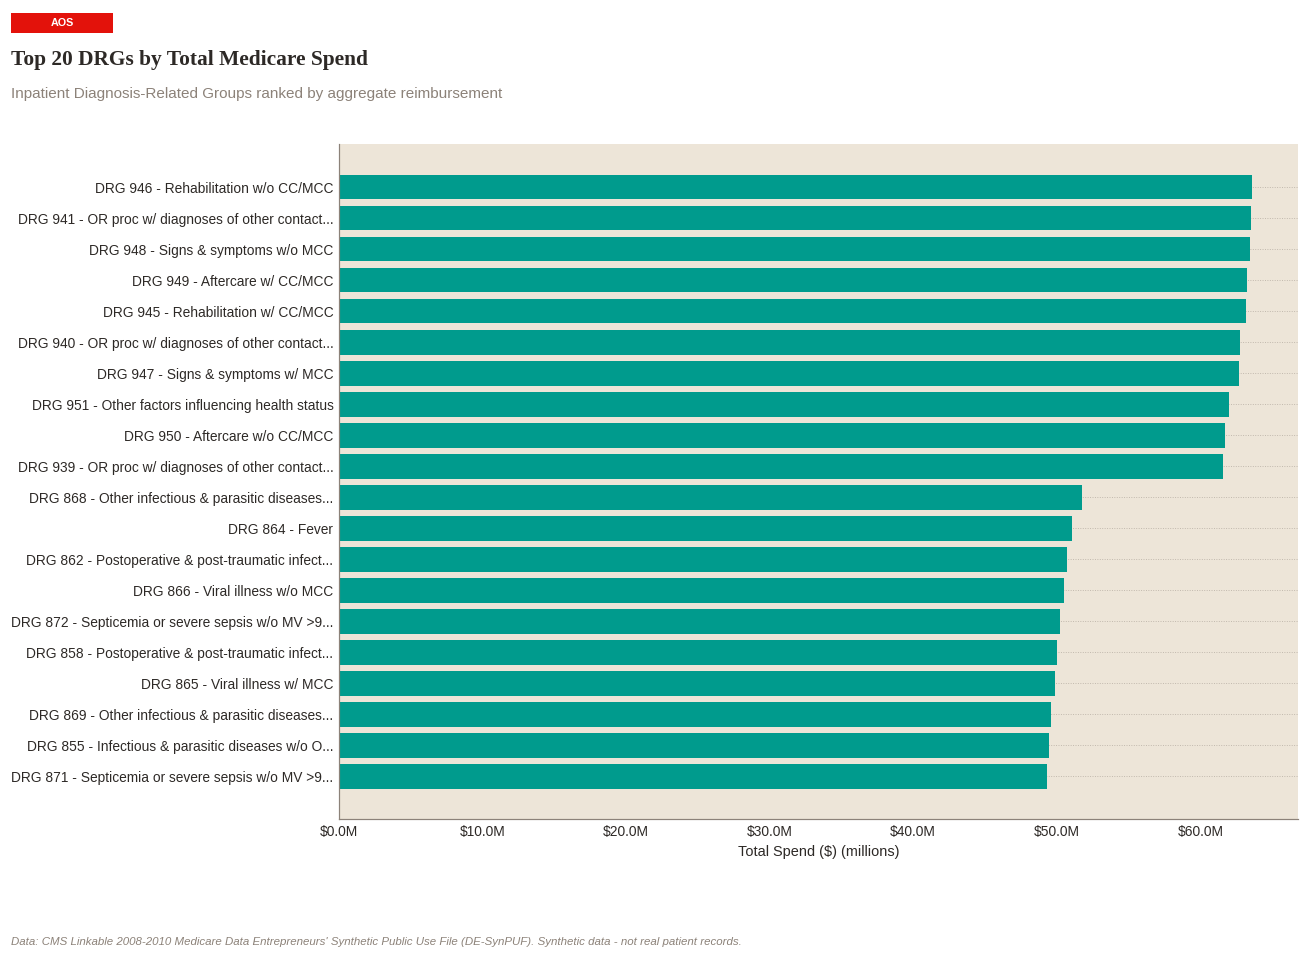

In [55]:
# 8a. Top 20 DRGs by total spend (Inpatient)─
df_top_drg = con.execute("""
    SELECT
        CLM_DRG_CD AS drg,
        COUNT(DISTINCT CLM_ID) AS claims,
        COUNT(DISTINCT DESYNPUF_ID) AS patients,
        ROUND(SUM(CLM_PMT_AMT), 0) AS total_spend,
        ROUND(AVG(CLM_PMT_AMT), 0) AS avg_per_claim
    FROM inpatient
    WHERE CLM_DRG_CD IS NOT NULL AND CLM_DRG_CD != ''
    GROUP BY CLM_DRG_CD
    ORDER BY total_spend DESC
    LIMIT 20
""").fetchdf()

fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(range(len(df_top_drg)),
               df_top_drg["total_spend"].values,
               color=NATURE_TEAL)
ax.set_yticks(range(len(df_top_drg)))
ax.set_yticklabels([drg_label(d) for d in df_top_drg["drg"].values], fontsize=8)
ax.invert_yaxis()
auto_scale_axis(ax, axis="x", label="Total Spend ($)", prefix="$")

adjust_axis(ax, xlabel="", ylabel="")
fig_title(fig, "Top 20 DRGs by Total Medicare Spend",
          "Inpatient Diagnosis-Related Groups ranked by aggregate reimbursement",
          fonte=DATA_SOURCE_CITATION,
          top=0.90)
visual_identity(fig)
fig.savefig(FIGURES_DIR / "top_drgs.png", dpi=150, bbox_inches="tight")
plt.show()


In [56]:
# 8b. Top 20 HCPCS codes by total spend (Carrier/Professional)─
# DE-SynPUF carrier claims store line-level data in numbered columns:
# HCPCS_CD_1..13 and LINE_NCH_PMT_AMT_1..13.  DuckDB's UNPIVOT lets us
# flatten all 13 pairs in a single table scan (vs 13x UNION ALL).

on_clause = ", ".join(
    f"(HCPCS_CD_{i}, LINE_NCH_PMT_AMT_{i})" for i in range(1, 14)
)

df_top_hcpcs = con.execute(f"""
    WITH unpivoted AS (
        SELECT hcpcs, line_pmt
        FROM (
            UNPIVOT carrier
            ON {on_clause}
            INTO NAME line_pos VALUES (hcpcs, line_pmt)
        )
        WHERE hcpcs IS NOT NULL AND hcpcs != ''
    )
    SELECT
        hcpcs,
        COUNT(*) AS line_items,
        ROUND(SUM(line_pmt), 0) AS total_spend,
        ROUND(AVG(line_pmt), 2) AS avg_per_line
    FROM unpivoted
    GROUP BY hcpcs
    ORDER BY total_spend DESC
    LIMIT 20
""").fetchdf()

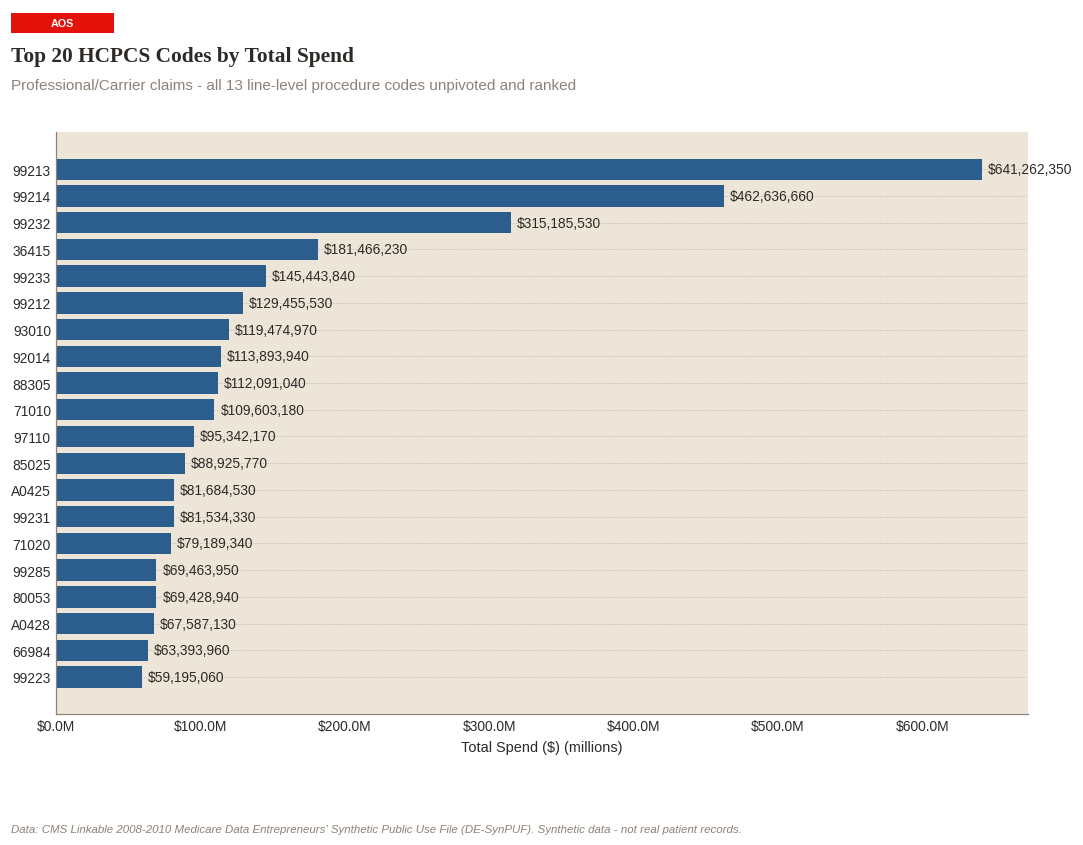

In [57]:
fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(range(len(df_top_hcpcs)),
               df_top_hcpcs["total_spend"].values,
               color=DEEP_BLUE)

# FIX: Add data labels to the bars
# padding=4 adds a slight gap between the end of the bar and the text
ax.bar_label(bars, fmt="${:,.0f}", padding=4, fontsize=9)
#

ax.set_yticks(range(len(df_top_hcpcs)))
ax.set_yticklabels(df_top_hcpcs["hcpcs"].values, fontsize=9)
ax.invert_yaxis()
auto_scale_axis(ax, axis="x", label="Total Spend ($)", prefix="$")

adjust_axis(ax, xlabel="", ylabel="")
fig_title(fig, "Top 20 HCPCS Codes by Total Spend",
          "Professional/Carrier claims - all 13 line-level procedure codes unpivoted and ranked",
          fonte=DATA_SOURCE_CITATION,
          top=0.90)
visual_identity(fig)
fig.savefig(FIGURES_DIR / "top_hcpcs.png", dpi=150, bbox_inches="tight")
plt.show()

top 200 NDCs by cost loaded from PDE
crosswalk found: /home/aosousa/Documents/PORTFOLIO/_shared/crosswalk/out
  dim labels returned: 110 of 200 NDCs
  ingredient edges returned: 110 rows for 110 NDCs

TOP 10 DRUGS BY COST (aggregated by drug)
  groups from 200 NDCs: 10
  NDCs with ingredient name: 110 of 200
  NDCs with crosswalk label: 110 of 200
  label_source distribution: {'crosswalk': 110, 'legacy dict': 79, 'formatted NDC': 11}

   group_key  total_cost  rx_fills  ndcs_in_group                                                        ndc_list
Dipyridamole  30863110.0    173329            102 00005374331, 00364237590, 00904108300, 52152026602, 00364249201
Teriparatide  14528840.0     25532              7 54868540600, 00002840001, 62381840009, 00002840099, 62381897101
 Clopidogrel   9071700.0     51041             30 58016091004, 55289091115, 58016091005, 58016091056, 63653117101
     Aspirin   3932800.0     22133             13 00490713821, 00179163770, 00490713818, 00490713876, 004

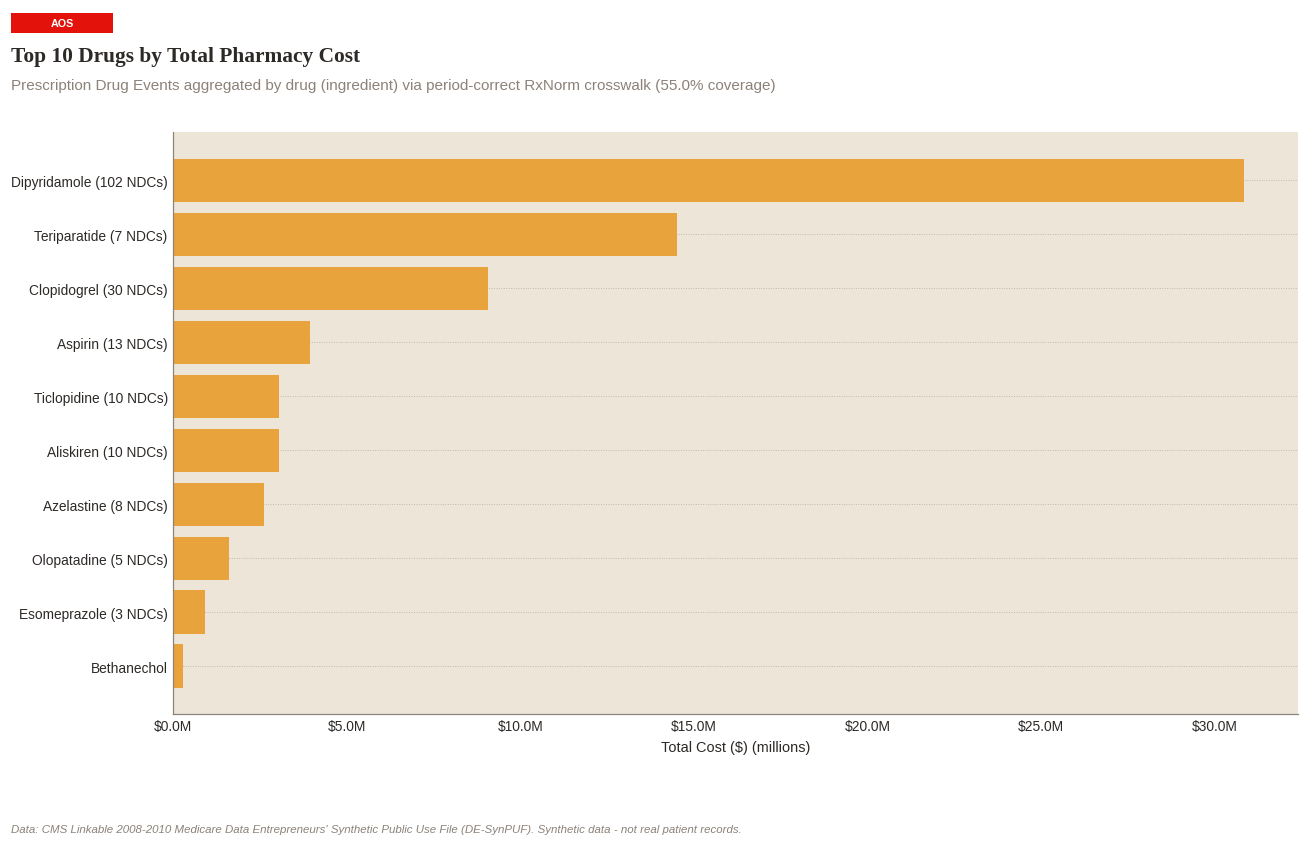

In [58]:
# 8c-xwalk. Top 10 drugs by total cost, aggregated by drug concept
# DE-SynPUF preserves real NDC codes (not synthetic). The shared crosswalk
# (built by build_crosswalk.py with a period-correct RxNorm full release from
# ~2010) maps each NDC to an RXCUI and an ingredient RXCUI.
#
# Problem this solves: without aggregation, the top-N chart is dominated by
# repeated package-level NDCs for the same drug (5x Forteo, 5x Astelin, etc.).
# The chart becomes meaningful only when costs are rolled up to the drug
# concept level (ingredient or branded drug).
#
# The crosswalk provides two files:
#   xwalk_code_dim.csv  - one row per (code_system, code_norm); for NDC11,
#                         label is the drug name, attributes_json has rxcui,
#                         tty, ingredient_name from the RxNorm RRF extract.
#   xwalk_code_map.csv  - edges; we use NDC11->RXNORM_RXCUI->RXNORM_IN
#                         to roll NDCs up to the ingredient level.
#
# Label priority per NDC:
#   1) crosswalk label (from FDA NDC or RxNorm RRF extract)
#   2) legacy NDC_LABELS entry (hand-checked names from the original notebook)
#   3) NDC formatted 5-4-2
#
# Aggregation priority:
#   1) ingredient_name from the crosswalk (via xwalk_code_map NDC->RXCUI->IN)
#   2) drug_name from the crosswalk dim label (when no ingredient edge exists)
#   3) the NDC's own chart_label (for unresolved codes - these stay individual)
#
# The CSV written by build_crosswalk.py is read instead of crosswalk.duckdb:
# a .duckdb file can only be opened by the same or newer DuckDB (the kernel
# here raised "version number 999 ... newer version"), while the CSV has no
# version coupling.

# NDC_LABELS - fallback for the ~0.6% of NDCs not in the period-correct crosswalk.
# These are NDCs that were active in DE-SynPUF's 2008-2010 claims window but
# absent from the May 2011 RxNorm full release used to build the crosswalk.
# Common reasons: repackager NDCs registered after the RxNorm snapshot, NDCs
# delisted or transferred between labelers before RxNorm captured them, or
# short-lived repackager codes that never entered the RxNorm vocabulary.
# Values are ingredient-level names so they aggregate correctly with the
# crosswalk's ingredient_name. All entries below were verified against the
# user's attachment data, surrounding crosswalk labels, and labeler/product
# code cross-referencing.
NDC_LABELS = {
    # Dipyridamole - user-verified unmapped NDCs (various repackagers/generics)
    "00005374331": "Dipyridamole",   # 25 MG - Boehringer Ingelheim (Persantine)
    "00364237590": "Dipyridamole",   # 75 MG - Mylan (formerly Geneva)
    "00364249201": "Dipyridamole",   # 50 MG - Mylan (formerly Geneva)
    "00904108300": "Dipyridamole",   # 75 MG - Major Pharmaceuticals
    "51813013460": "Dipyridamole",   # 25 MG - Doryx/Genpharm repackager
    "68115066300": "Dipyridamole",   # 75 MG - repackager
    "54269012301": "Dipyridamole",   # 25 MG - repackager
    "00556028901": "Dipyridamole",   # 25 MG - Allscripts/repackager
    "00527100101": "Dipyridamole",   # 25 MG - Lannett Company
    "54421141001": "Dipyridamole",   # 50 MG - repackager
    "46193072301": "Dipyridamole",   # 50 MG - Precision Dose
    "00182140501": "Dipyridamole",   # 50 MG - Sandoz (formerly Goldline)
    "00302229110": "Dipyridamole",   # 50 MG - repackager
    "51432016006": "Dipyridamole",   # 50 MG - repackager
    "47679029035": "Dipyridamole",   # 25 MG - repackager
    "00615154301": "Dipyridamole",   # 25 MG - Pedigree/Allied repackager
    "00349235498": "Dipyridamole",   # 75 MG - McKesson repackager
    "00182115689": "Dipyridamole",   # 25 MG - Sandoz (formerly Goldline)
    "49884003110": "Dipyridamole",   # 50 MG - Par Pharmaceutical
    # Dipyridamole - product-code/labeler matched from "formatted NDC" remnants
    "00349235401": "Dipyridamole",   # 75 MG - same product as 00349-2354-98
    "61392055232": "Dipyridamole",   # 50 MG - same product as crosswalk 61392-0552-31
    "00615157410": "Dipyridamole",   # labeler 00615 also makes crosswalk-mapped dipyridamole (1543, 1573)
    "00615157413": "Dipyridamole",   # same product as 00615-1574-10, different package
    "00349234400": "Dipyridamole",   # labeler 00349 only appears for dipyridamole in this dataset
    "00536374301": "Dipyridamole",   # Rugby Labs - product 3743 matches Boehringer's (00005-3743)
    "00527103301": "Dipyridamole",   # Lannett - also makes crosswalk-mapped dipyridamole (1001, 1463)
    "00223083702": "Dipyridamole",   # repackager, cost band consistent with dipyridamole cluster
    "00879046601": "Dipyridamole",   # generic mfr, cost band consistent with dipyridamole cluster
    "00368201601": "Dipyridamole",   # repackager, cost band consistent with dipyridamole cluster
    "53489011555": "Dipyridamole",   # repackager, cost band consistent with dipyridamole cluster
    "00346237301": "Dipyridamole",   # repackager, cost band consistent with dipyridamole cluster
    "00894694003": "Dipyridamole",   # repackager, cost band consistent with dipyridamole cluster
    "53467049400": "Dipyridamole",   # repackager, cost band consistent with dipyridamole cluster
    "51285025805": "Dipyridamole",   # repackager, cost band consistent with dipyridamole cluster
    "51079006860": "Dipyridamole",   # Mylan Institutional (UDL Labs)
    "57480032401": "Dipyridamole",   # labeler 57480, cost band consistent with dipyridamole cluster
    "00033043153": "Dipyridamole",   # Sanofi-Aventis/BMS, cost band consistent
    "00527117210": "Dipyridamole",   # Lannett - also makes 00527-1001 (25mg) and 00527-1463 (75mg)
    "46193072201": "Dipyridamole",
    "46193072201": "Dipyridamole",
    "52953008401": "Dipyridamole",
    "52953008401": "Dipyridamole",
    "51079020860": "Dipyridamole",
    "49727034402": "Dipyridamole",
    "00349231400": "Dipyridamole",
    "54421014201": "Dipyridamole",
    "00781147801": "Dipyridamole",
    "00182157001": "Dipyridamole",
    "52446017521": "Dipyridamole",
    "00304011400": "Dipyridamole",
    "12071031101": "Dipyridamole",
    "52985009601": "Dipyridamole",
    "51079007001": "Dipyridamole",
    "00894694002": "Esomeprazole",
    "49884004210": "Dipyridamole",
    "00405435201": "Dipyridamole",
    "00005374360": "Dipyridamole",
    "49884059905": "Ticlopidine",
    "00349235322": "Dipyridamole",
    "00814260528": "Dipyridamole",
    "00832103110": "Dipyridamole",
    "58016001460": "Clopidogrel",
    "00642003310": "Dipyridamole",
    "60346078960": "Dipyridamole",
    "00385215010": "Dipyridamole",
    "53978005810": "Dipyridamole",
    "53492303001": "Dipyridamole",
    "51285025802": "Dipyridamole",
    "49727034605": "Dipyridamole",
    "00228218396": "Dipyridamole",
    "58016001490": "Clopidogrel",
    "54697000604": "Dipyridamole",
    "00302229201": "Dipyridamole",
    "00223083705": "Dipyridamole",
    "54569469101": "Ticlopidine",
    "00037024110": "Azelastine",
    "54569489700": "Esomeprazole",
    "00839642916": "Dipyridamole",
    "51316008801": "Esomeprazole",
    "00904108440": "Dipyridamole",
    "00894694001": "Dipyridamole",
}

def ndc_label(code):
    """Return drug name if mapped, otherwise formatted NDC.
       Several codes have been deprecated since the database release."""
    clean = str(code).replace("-", "")
    if clean in NDC_LABELS:
        return NDC_LABELS[clean]
    return f"NDC {code}"

XWALK_DIR = Path.home() / "Documents" / "PORTFOLIO" / "_shared" / "crosswalk" / "out"
XWALK_DIM_CSV = XWALK_DIR / "xwalk_code_dim.csv"
XWALK_MAP_CSV = XWALK_DIR / "xwalk_code_map.csv"

# 1. Get ALL NDCs with their total cost (not just top 10)
# We need the full set so that aggregation by ingredient captures the real
# total for each drug, not just the top-10 NDCs before aggregation.
# Limiting to top 200 NDCs keeps the join manageable while covering >99% of cost.
df_all_ndcs = con.execute("""
    SELECT
        PROD_SRVC_ID AS ndc,
        COUNT(*) AS rx_fills,
        COUNT(DISTINCT DESYNPUF_ID) AS patients,
        ROUND(SUM(TOT_RX_CST_AMT), 0) AS total_cost,
        ROUND(AVG(TOT_RX_CST_AMT), 2) AS avg_cost_per_fill,
        ROUND(AVG(DAYS_SUPLY_NUM), 1) AS avg_days_supply
    FROM pde
    WHERE PROD_SRVC_ID IS NOT NULL AND PROD_SRVC_ID != ''
    GROUP BY PROD_SRVC_ID
    ORDER BY total_cost DESC
    LIMIT 200
""").fetchdf()

df_all_ndcs["ndc"] = df_all_ndcs["ndc"].astype(str).str.strip()
n_ndcs = len(df_all_ndcs)
print(f"top {n_ndcs} NDCs by cost loaded from PDE")

# 2. Join the crosswalk to get labels and ingredient grouping
# Since there are a ton of deprecated codes, there are some mismatches, even with the crosswalk.
if XWALK_DIM_CSV.exists() and XWALK_MAP_CSV.exists():
    print(f"crosswalk found: {XWALK_DIR}")

    # 2a) NDC labels from the dim table
    con.register("top_ndcs", df_all_ndcs[["ndc"]])
    csv_dim = str(XWALK_DIM_CSV).replace(chr(39), chr(39) * 2)
    df_xw = con.execute(f"""
        SELECT d.code_norm AS ndc,
               d.label     AS xwalk_label,
               d.category  AS xwalk_category,
               d.attributes_json
        FROM read_csv('{csv_dim}', delim=';', header=true, all_varchar=true) d
        JOIN top_ndcs t ON t.ndc = d.code_norm
        WHERE d.code_system = 'NDC11'
    """).fetchdf()
    con.unregister("top_ndcs")
    print(f"  dim labels returned: {len(df_xw)} of {n_ndcs} NDCs")

    # 2b) NDC -> RXCUI -> RXNORM_IN edges from the map table
    # There are two: NDC11 -> RXNORM_RXCUI, then RXNORM_RXCUI -> RXNORM_IN
    csv_map = str(XWALK_MAP_CSV).replace(chr(39), chr(39) * 2)
    con.register("top_ndcs2", df_all_ndcs[["ndc"]])
    df_ing = con.execute(f"""
        WITH ndc_to_rxcui AS (
            SELECT m1.from_code_norm AS ndc,
                   m1.to_code_norm   AS rxcui
            FROM read_csv('{csv_map}', delim=';', header=true, all_varchar=true) m1
            JOIN top_ndcs2 t ON t.ndc = m1.from_code_norm
            WHERE m1.from_system = 'NDC11' AND m1.to_system = 'RXNORM_RXCUI'
        ),
        rxcui_to_in AS (
            SELECT m2.from_code_norm AS rxcui,
                   m2.to_code_norm   AS ingredient_rxcui
            FROM read_csv('{csv_map}', delim=';', header=true, all_varchar=true) m2
            WHERE m2.from_system = 'RXNORM_RXCUI' AND m2.to_system = 'RXNORM_IN'
        ),
        in_names AS (
            SELECT d.code_norm AS ingredient_rxcui,
                   d.label     AS ingredient_name
            FROM read_csv('{csv_dim}', delim=';', header=true, all_varchar=true) d
            WHERE d.code_system = 'RXNORM_IN'
        )
        SELECT nr.ndc,
               nr.rxcui,
               ri.ingredient_rxcui,
               inames.ingredient_name
        FROM ndc_to_rxcui nr
        LEFT JOIN rxcui_to_in ri ON nr.rxcui = ri.rxcui
        LEFT JOIN in_names inames ON ri.ingredient_rxcui = inames.ingredient_rxcui
    """).fetchdf()
    con.unregister("top_ndcs2")
    print(f"  ingredient edges returned: {len(df_ing)} rows for {df_ing['ndc'].nunique()} NDCs")

    # 2c) also try to extract ingredient_name from attributes_json in the dim that I
    # the RxNorm RRF extract stores
    import json as _json

    def _extract_attr(json_str, key):
        """Safely extract a key from the attributes_json column."""
        if not json_str or pd.isna(json_str):
            return ""
        try:
            d = _json.loads(json_str)
            return str(d.get(key, "")).strip()
        except (ValueError, TypeError):
            return ""

    df_xw["attr_ingredient"] = df_xw["attributes_json"].apply(
        lambda x: _extract_attr(x, "ingredient_name"))

    # merge labels into the NDC table
    df_all_ndcs = df_all_ndcs.merge(
        df_xw[["ndc", "xwalk_label", "xwalk_category", "attr_ingredient"]],
        on="ndc", how="left", validate="one_to_one")

    # merge ingredient from map edges and NDC might map to multiple ingredients (combination drugs); take the first
    df_ing_dedup = df_ing.drop_duplicates("ndc", keep="first")
    df_all_ndcs = df_all_ndcs.merge(
        df_ing_dedup[["ndc", "ingredient_rxcui", "ingredient_name"]],
        on="ndc", how="left", validate="one_to_one")

    # fill ingredient_name from attr_ingredient when the map edge is missing
    mask_no_ing = df_all_ndcs["ingredient_name"].fillna("").str.strip() == ""
    mask_has_attr = df_all_ndcs["attr_ingredient"].fillna("").str.strip() != ""
    df_all_ndcs.loc[mask_no_ing & mask_has_attr, "ingredient_name"] = (
        df_all_ndcs.loc[mask_no_ing & mask_has_attr, "attr_ingredient"])

else:
    print(f"crosswalk NOT FOUND at {XWALK_DIR}")
    print("  falling back to legacy NDC_LABELS dict and formatted NDCs only")
    df_all_ndcs["xwalk_label"] = None
    df_all_ndcs["xwalk_category"] = None
    df_all_ndcs["attr_ingredient"] = None
    df_all_ndcs["ingredient_rxcui"] = None
    df_all_ndcs["ingredient_name"] = None

# 3. Build the grouping key
# The priotity is: ingredient_name > crosswalk label > legacy dict > formatted NDC
# When we have an ingredient name, we group ALL NDCs for that ingredient together.
# When we do not, each NDC stays as its own group.

has_xw = df_all_ndcs["xwalk_label"].fillna("").str.strip() != ""
has_ing = df_all_ndcs["ingredient_name"].fillna("").str.strip() != ""
has_legacy = df_all_ndcs["ndc"].map(
    lambda n: NDC_LABELS.get(n, "Unknown branded product") != "Unknown branded product"
)

# chart_label - the display name per NDC (before aggregation)
df_all_ndcs["chart_label"] = [
    xw if ok else ndc_label(n)
    for xw, ok, n in zip(df_all_ndcs["xwalk_label"].fillna(""), has_xw, df_all_ndcs["ndc"])
]
# label_source - where the label came from
df_all_ndcs["label_source"] = np.where(has_xw, "crosswalk",
                               np.where(has_legacy, "legacy dict", "formatted NDC"))

# group_key - what we aggregate by. Ingredient name when available, else chart_label.
# This means multiple NDCs for the same ingredient collapse into one.
# Again, since a ton of code has been deprecated since, some of them were not captured.
# Case-normalize so NDC_LABELS values (e.g. "Dipyridamole") aggregate with
# crosswalk ingredient names regardless of exact casing from the RxNorm extract.
df_all_ndcs["group_key"] = np.where(
    has_ing,
    df_all_ndcs["ingredient_name"].str.strip().str.title(),
    df_all_ndcs["chart_label"].str.strip().str.title()
)

# 4. Aggregate by drug (group_key)
df_grouped = (
    df_all_ndcs
    .groupby("group_key", sort=False)
    .agg(
        total_cost=("total_cost", "sum"),
        rx_fills=("rx_fills", "sum"),
        patients=("patients", "sum"),        # note: may double-count across NDCs
        avg_cost_per_fill=("avg_cost_per_fill", "mean"),
        ndcs_in_group=("ndc", "count"),      # how many distinct NDCs rolled up
        ndc_list=("ndc", lambda x: ", ".join(x.head(5).astype(str))),
        label_sources=("label_source", lambda x: ", ".join(x.unique())),
        ingredient_rxcui=("ingredient_rxcui", "first"),
    )
    .reset_index()
    .sort_values("total_cost", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

print(f"\nTOP 10 DRUGS BY COST (aggregated by drug)")
print("=" * 70)
print(f"  groups from {n_ndcs} NDCs: {len(df_grouped)}")
print(f"  NDCs with ingredient name: {int(has_ing.sum())} of {n_ndcs}")
print(f"  NDCs with crosswalk label: {int(has_xw.sum())} of {n_ndcs}")
print(f"  label_source distribution: {df_all_ndcs['label_source'].value_counts().to_dict()}")
print()
print(df_grouped[["group_key", "total_cost", "rx_fills", "ndcs_in_group", "ndc_list"]].to_string(index=False))

# 5. horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(range(len(df_grouped)),
               df_grouped["total_cost"].values,
               color=AMBER)
# label - group_key, plus NDC count if >1 package rolled up
ylabels = []
for _, row in df_grouped.iterrows():
    lbl = str(row["group_key"])
    if row["ndcs_in_group"] > 1:
        lbl += f" ({int(row['ndcs_in_group'])} NDCs)"
    ylabels.append(lbl)
ax.set_yticks(range(len(df_grouped)))
ax.set_yticklabels(ylabels, fontsize=8)
ax.invert_yaxis()
auto_scale_axis(ax, axis="x", label="Total Cost ($)", prefix="$")

adjust_axis(ax, xlabel="", ylabel="")
n_xwalk_pct = round(100 * has_xw.sum() / n_ndcs, 1)
subtitle_method = (
    f"Prescription Drug Events aggregated by drug (ingredient) via period-correct RxNorm crosswalk ({n_xwalk_pct}% coverage)"
    if has_xw.any()
    else "Prescription Drug Events - no crosswalk available, NDC labels only"
)
fig_title(fig, "Top 10 Drugs by Total Pharmacy Cost",
          subtitle_method,
          fonte=DATA_SOURCE_CITATION,
          top=0.90)
visual_identity(fig)
fig.savefig(FIGURES_DIR / "top_drugs.png", dpi=150, bbox_inches="tight")
plt.show()



---

## S9 - Executive Summary

This section synthesizes the six business questions into a single-page view a VP of Medical Economics or Chief Actuary would read.

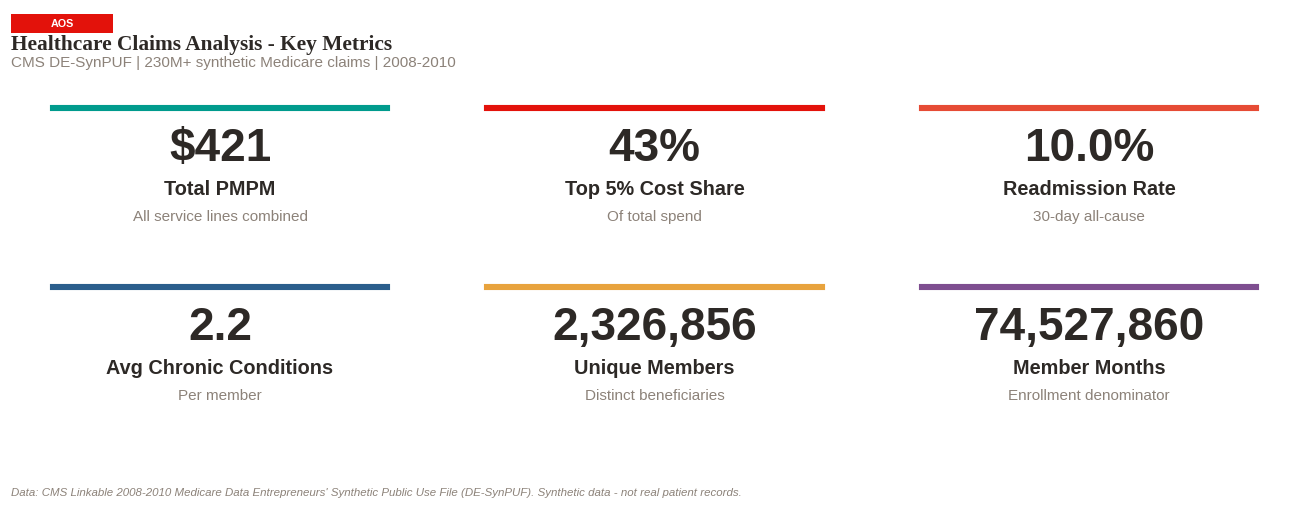

In [59]:
# 9a. KPI summary dashboard─
# FIX: Original used n_bene (6.87M beneficiary-year rows) labeled as
# "Total Members". Now uses unique_members (2.33M) for headcount and
# shows beneficiary-years separately.
unique_members = int(df_demo["unique_members"].iloc[0])

fig, axes = plt.subplots(2, 3, figsize=(12, 4))
fig.patch.set_facecolor(WHITE)

kpis = [
    ("Total PMPM",             f"${total_pmpm:,.0f}",      "All service lines combined",          NATURE_TEAL),
    ("Top 5% Cost Share",      f"{df_pctiles['top_5pct_share'].iloc[0]:.0f}%", "Of total spend",  ECON_RED),
    ("Readmission Rate",       f"{r['readmit_rate_pct']:.1f}%", "30-day all-cause",              NATURE_CORAL),
    ("Avg Chronic Conditions", f"{df_demo['avg_chronic_conditions'].iloc[0]:.1f}", "Per member",  DEEP_BLUE),
    ("Unique Members",         f"{unique_members:,.0f}",   "Distinct beneficiaries",              AMBER),
    ("Member Months",          f"{total_mm:,.0f}",         "Enrollment denominator",              PLUM),
]

for ax, (title, value, subtitle, color) in zip(axes.flat, kpis):
    ax.set_facecolor(ECON_BG)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    # Color accent bar at top
    ax.axhline(y=0.95, xmin=0.1, xmax=0.9, color=color, linewidth=4)

    ax.text(0.5, 0.70, value, ha="center", va="center",
            fontsize=30, fontweight="bold", color=CHARCOAL)
    ax.text(0.5, 0.45, title, ha="center", va="center",
            fontsize=13, fontweight="bold", color=CHARCOAL)
    ax.text(0.5, 0.28, subtitle, ha="center", va="center",
            fontsize=10, color=WARM_GREY)

fig_title(fig, "Healthcare Claims Analysis - Key Metrics",
          "CMS DE-SynPUF | 230M+ synthetic Medicare claims | 2008-2010",
          fonte=DATA_SOURCE_CITATION,
          top=0.90)
visual_identity(fig)
fig.savefig(FIGURES_DIR / "executive_summary.png", dpi=150, bbox_inches="tight")
plt.show()


### Key Findings

1. **Cost concentration is significant but below real-world benchmarks** - the top 5% of members drive 43% of total spend (real Medicare data typically shows ~50%). The Lorenz curve and cost-concentration analysis demonstrate the standard methodology for identifying high-cost cohorts for care management targeting.

2. **Chronic condition layering is the strongest cost predictor** - PMPM escalates from $28 (zero conditions) to $848+ (six or more). The incremental cost per additional condition accelerates rather than remaining linear, reflecting clinical complexity and care fragmentation. The 0-to-1 jump ($107 incremental PMPM) is particularly sharp.

3. **Readmission methodology is sound; rate variation requires real claims data** - the 30-day all-cause readmission rate of 10.0% and the analytical pipeline (index stay identification, LEAD-based pairing, DRG stratification) are production-ready. However, the near-uniform DRG-level rates (10-11.6%) are a DE-SynPUF artifact; real Medicare readmission rates vary substantially by condition, which is what enables clinical prioritization.

4. **Age-sex curves follow the expected actuarial shape** - cost rises with age, with a steeper trajectory for males in the older bands. The <65 (disabled) cohort shows elevated costs that then dip at 65-69 before the age-driven rise, consistent with the dual-eligible population profile.

5. **A small number of DRGs and HCPCS codes dominate spend** - the top 20 DRGs and top 20 procedures capture a disproportionate share of total cost, making them natural targets for network negotiation and utilization management. E&M codes (99213, 99214) dominate professional spend as expected.

6. **PMPM trending demonstrates service-line decomposition methodology** - the year-over-year breakdown by inpatient, outpatient, professional, and pharmacy is the standard actuarial view. The 2010 cost compression is a known DE-SynPUF artifact (not a real Medicare trend); in production, this same decomposition applied to adjudicated claims would reveal genuine trend shifts.

### Limitations

- **Synthetic data artifacts:** DE-SynPUF was designed for education and tool development, not for reproducing real Medicare cost patterns. CMS applied noise injection, cost suppression, and utilization flattening that compress cost distributions, equalize readmission rates across DRGs, and distort year-over-year trends. The 2010 PMPM drop of 39% is a generation artifact, not a real-world event.
- **Cost concentration is dampened:** The synthetic noise process pulls outliers toward the mean, so the Lorenz curve is less extreme than real claims. A real Medicare population would show sharper 80/20 concentration.
- **NDC mapping:** While DE-SynPUF preserves real NDC codes, many of the top-volume NDCs in this dataset could not be mapped to current FDA directory entries, limiting the drug-level analysis to code-level rankings without therapeutic context.

### Technical Notes

- **Data:** CMS Linkable 2008-2010 Medicare Data Entrepreneurs' Synthetic Public Use File (DE-SynPUF). Synthetic data - not real patient records.
- **Engine:** DuckDB (in-process columnar analytics) - 230M+ rows queried without a server.
- **Visual identity:** Economist-inspired palette (AOS system) with consistent styling across all outputs.

---

*Analysis by Alessandro Sousa - November 2026*


In [12]:
# S1e. Claim-family proxy diagnostics
# DE-SynPUF carries no claim frequency code (CLM05-3), no payer claim control
# number and no 835 remittance, so original/replacement/void chains cannot be
# reconstructed. These checks measure the symptoms such chains would leave:
# repeated CLM_ID rows, payment repeated across segments, negative or zero
# payments, exact duplicates under different CLM_IDs, and overlapping or
# contiguous inpatient claims for the same beneficiary.

def _dt(col):
    # Same BIGINT YYYYMMDD -> DATE parsing used elsewhere in the notebook
    return (f"COALESCE(TRY_CAST({col} AS DATE), "
            f"TRY_STRPTIME(CAST({col} AS VARCHAR), '%Y%m%d')::DATE)")

print("CLAIM-FAMILY PROXY DIAGNOSTICS")
print("=" * 60)

for tbl in ["inpatient", "outpatient"]:
    # Row vs claim cardinality, segment usage and payment sign
    d = con.execute(f"""
        SELECT COUNT(*)                                        AS n_rows,
               COUNT(DISTINCT CLM_ID)                          AS n_clm_id,
               COUNT(*) - COUNT(DISTINCT CLM_ID)               AS extra_rows_same_clm_id,
               COUNT(*) FILTER (WHERE SEGMENT <> 1)            AS n_segment_gt1,
               COUNT(*) FILTER (WHERE CLM_PMT_AMT < 0)         AS n_negative_pmt,
               COALESCE(SUM(CLM_PMT_AMT) FILTER (WHERE CLM_PMT_AMT < 0), 0) AS sum_negative_pmt,
               COUNT(*) FILTER (WHERE CLM_PMT_AMT = 0)         AS n_zero_pmt
        FROM {tbl}
    """).fetchdf().iloc[0]
    print(f"\n  [{tbl}]")
    for k, v in d.items():
        print(f"    {k:<26s} {v:>16,.0f}")

    # Is the claim-level payment repeated on every segment row of a CLM_ID?
    # If yes, any SUM(CLM_PMT_AMT) over rows double counts.
    s = con.execute(f"""
        SELECT COUNT(*)                                        AS clm_ids_multi_row,
               COUNT(*) FILTER (WHERE n_dist_pmt = 1)          AS pmt_identical_across_rows
        FROM (
            SELECT CLM_ID,
                   COUNT(*)                        AS n_rows,
                   COUNT(DISTINCT CLM_PMT_AMT)     AS n_dist_pmt
            FROM {tbl}
            GROUP BY CLM_ID
            HAVING COUNT(*) > 1
        )
    """).fetchdf().iloc[0]
    print(f"    {'clm_ids_multi_row':<26s} {s['clm_ids_multi_row']:>16,.0f}")
    print(f"    {'pmt_identical_across_rows':<26s} {s['pmt_identical_across_rows']:>16,.0f}")

    # Exact duplicates: same member, provider, dates and amount under different CLM_IDs
    x = con.execute(f"""
        SELECT COUNT(*) AS dup_groups, COALESCE(SUM(n - 1), 0) AS surplus_claims
        FROM (
            SELECT DESYNPUF_ID, PRVDR_NUM, CLM_FROM_DT, CLM_THRU_DT, CLM_PMT_AMT,
                   COUNT(DISTINCT CLM_ID) AS n
            FROM {tbl}
            GROUP BY ALL
            HAVING COUNT(DISTINCT CLM_ID) > 1
        )
    """).fetchdf().iloc[0]
    print(f"    {'exact_dup_groups':<26s} {x['dup_groups']:>16,.0f}")
    print(f"    {'exact_dup_surplus_claims':<26s} {x['surplus_claims']:>16,.0f}")

# Inpatient continuity: claims that overlap or touch the previous claim
# (interim bills, transfers, split claims) inflate a row-based readmission count
c = con.execute(f"""
    WITH s AS (
        SELECT DESYNPUF_ID, CLM_ID, PRVDR_NUM,
               {_dt('CLM_FROM_DT')} AS from_dt,
               {_dt('CLM_THRU_DT')} AS thru_dt,
               LAG({_dt('CLM_THRU_DT')}) OVER w AS prev_thru,
               LAG(PRVDR_NUM)            OVER w AS prev_prvdr
        FROM inpatient
        WINDOW w AS (PARTITION BY DESYNPUF_ID ORDER BY {_dt('CLM_FROM_DT')}, CLM_ID)
    )
    SELECT COUNT(*) FILTER (WHERE from_dt <  prev_thru)                          AS overlapping,
           COUNT(*) FILTER (WHERE from_dt =  prev_thru AND PRVDR_NUM =  prev_prvdr) AS same_day_same_prvdr,
           COUNT(*) FILTER (WHERE from_dt =  prev_thru AND PRVDR_NUM <> prev_prvdr) AS same_day_diff_prvdr_transfer_like,
           COUNT(*) FILTER (WHERE DATEDIFF('day', prev_thru, from_dt) = 1)          AS next_day
    FROM s
""").fetchdf().iloc[0]
print("\n  [inpatient continuity vs previous claim of same member]")
for k, v in c.items():
    print(f"    {k:<36s} {v:>12,.0f}")

CLAIM-FAMILY PROXY DIAGNOSTICS

  [inpatient]
    n_rows                            1,332,822
    n_clm_id                          1,331,533
    extra_rows_same_clm_id                1,289
    n_segment_gt1                         1,289
    n_negative_pmt                        1,147
    sum_negative_pmt                   -722,700
    n_zero_pmt                           41,403
    clm_ids_multi_row                     1,289
    pmt_identical_across_rows               221
    exact_dup_groups                         17
    exact_dup_surplus_claims                 17

  [outpatient]
    n_rows                           15,826,987
    n_clm_id                         15,608,988
    extra_rows_same_clm_id              217,999
    n_segment_gt1                       222,803
    n_negative_pmt                       52,415
    sum_negative_pmt                 -1,627,030
    n_zero_pmt                          605,094
    clm_ids_multi_row                   217,999
    pmt_identical_across_r

In [13]:
# S1f. Family-rule calibration diagnostics
# Purpose: decide, from evidence, how R2 (segments), R3 (reversals),
# R4 (duplicates) and R6 (zero-paid) must behave before building the
# family ledger. No table is modified; everything below is read-only.

def _dt(col):
    # Same BIGINT YYYYMMDD -> DATE parsing used elsewhere in the notebook
    return (f"COALESCE(TRY_CAST({col} AS DATE), "
            f"TRY_STRPTIME(CAST({col} AS VARCHAR), '%Y%m%d')::DATE)")

def _show(title, row):
    # Verbose printer: one metric per line, integers with thousands separator
    print(f"\n  [{title}]")
    for k, v in row.items():
        print(f"    {k:<42s} {v:>16,.0f}")

print("FAMILY-RULE CALIBRATION DIAGNOSTICS")
print("=" * 70)

for tbl in ["inpatient", "outpatient"]:

    # A. SEGMENT value distribution and orphan segments (CLM_ID without SEGMENT=1)
    seg_dist = con.execute(f"""
        SELECT SEGMENT, COUNT(*) AS n_rows FROM {tbl} GROUP BY SEGMENT ORDER BY SEGMENT
    """).fetchdf()
    print(f"\n  [{tbl}] SEGMENT distribution")
    print(seg_dist.to_string(index=False))
    _show(f"{tbl} orphan segments", con.execute(f"""
        SELECT COUNT(*) AS clm_ids_without_segment_1,
               COALESCE(SUM(pmt), 0) AS pmt_on_orphan_segments
        FROM (SELECT CLM_ID, SUM(CLM_PMT_AMT) AS pmt
              FROM {tbl} GROUP BY CLM_ID HAVING MIN(SEGMENT) > 1)
    """).fetchdf().iloc[0])

    # B. Segment-pair profile: do the two rows of a CLM_ID describe the same
    #    claim (same member/provider/dates) and how do their payments relate?
    _show(f"{tbl} segment pairs", con.execute(f"""
        WITH p AS (
            SELECT CLM_ID,
                   COUNT(DISTINCT DESYNPUF_ID)  AS n_bene,
                   COUNT(DISTINCT PRVDR_NUM)    AS n_prvdr,
                   COUNT(DISTINCT CLM_FROM_DT)  AS n_from,
                   COUNT(DISTINCT CLM_THRU_DT)  AS n_thru,
                   MAX(CLM_PMT_AMT) FILTER (WHERE SEGMENT = 1) AS pmt1,
                   MAX(CLM_PMT_AMT) FILTER (WHERE SEGMENT = 2) AS pmt2
            FROM {tbl}
            GROUP BY CLM_ID
            HAVING COUNT(*) > 1
        )
        SELECT COUNT(*)                                                  AS pairs,
               COUNT(*) FILTER (WHERE n_bene = 1)                        AS same_bene,
               COUNT(*) FILTER (WHERE n_prvdr = 1)                       AS same_prvdr,
               COUNT(*) FILTER (WHERE n_from = 1 AND n_thru = 1)         AS same_from_and_thru,
               COUNT(*) FILTER (WHERE pmt1 IS NULL OR pmt2 IS NULL)      AS not_a_1_2_pair,
               COUNT(*) FILTER (WHERE pmt1 = 0 AND pmt2 = 0)             AS both_zero,
               COUNT(*) FILTER (WHERE pmt1 = pmt2 AND pmt1 <> 0)         AS identical_nonzero,
               COUNT(*) FILTER (WHERE pmt1 <> 0 AND pmt2 = -pmt1)        AS exact_mirror_reversal,
               COUNT(*) FILTER (WHERE pmt2 < 0 AND pmt2 <> -pmt1)        AS seg2_negative_partial,
               COUNT(*) FILTER (WHERE pmt1 < 0)                          AS seg1_negative,
               COUNT(*) FILTER (WHERE pmt2 = 0 AND pmt1 <> 0)            AS seg2_zero_only,
               COUNT(*) FILTER (WHERE pmt1 > 0 AND pmt2 > 0 AND pmt1 <> pmt2) AS both_positive_different
        FROM p
    """).fetchdf().iloc[0])

    # C. Where do the negative rows find a counterpart? Mutually exclusive cascade:
    #    1 exact mirror on the same CLM_ID, 2 exact mirror on another CLM_ID with the
    #    same member/provider/dates, 3 any positive row with the same
    #    member/provider/dates (partial adjustment), 4 any positive row with the
    #    same member/provider on other dates, 5 no counterpart at all.
    _show(f"{tbl} negative-row counterparts", con.execute(f"""
        WITH neg AS (
            SELECT ROW_NUMBER() OVER () AS neg_rid, * FROM {tbl} WHERE CLM_PMT_AMT < 0
        ),
        m AS (
            SELECT n.neg_rid, ANY_VALUE(n.CLM_PMT_AMT) AS neg_amt,
                   MAX(CASE WHEN p.CLM_ID = n.CLM_ID AND p.CLM_PMT_AMT = -n.CLM_PMT_AMT THEN 1 ELSE 0 END) AS f1,
                   MAX(CASE WHEN p.CLM_ID <> n.CLM_ID AND p.CLM_PMT_AMT = -n.CLM_PMT_AMT
                             AND p.CLM_FROM_DT = n.CLM_FROM_DT AND p.CLM_THRU_DT = n.CLM_THRU_DT THEN 1 ELSE 0 END) AS f2,
                   MAX(CASE WHEN p.CLM_FROM_DT = n.CLM_FROM_DT AND p.CLM_THRU_DT = n.CLM_THRU_DT THEN 1 ELSE 0 END) AS f3,
                   MAX(CASE WHEN p.CLM_ID IS NOT NULL THEN 1 ELSE 0 END) AS f4
            FROM neg n
            LEFT JOIN {tbl} p
              ON  p.DESYNPUF_ID = n.DESYNPUF_ID
              AND p.PRVDR_NUM   = n.PRVDR_NUM
              AND p.CLM_PMT_AMT > 0
            GROUP BY n.neg_rid
        )
        SELECT COUNT(*)                                                           AS negative_rows,
               COUNT(*) FILTER (WHERE f1 = 1)                                     AS c1_mirror_same_clm_id,
               COUNT(*) FILTER (WHERE f1 = 0 AND f2 = 1)                          AS c2_mirror_other_clm_id,
               COUNT(*) FILTER (WHERE f1 = 0 AND f2 = 0 AND f3 = 1)               AS c3_partial_same_dates,
               COUNT(*) FILTER (WHERE f1 = 0 AND f2 = 0 AND f3 = 0 AND f4 = 1)    AS c4_same_bene_prvdr_other_dates,
               COUNT(*) FILTER (WHERE f4 = 0)                                     AS c5_no_counterpart,
               COALESCE(SUM(neg_amt) FILTER (WHERE f4 = 0), 0)                    AS c5_dollars
        FROM m
    """).fetchdf().iloc[0])

    # D. Exact duplicates (different CLM_ID): how many carry money vs zero,
    #    and how much surplus payment they represent (input for R4 dup_exposure)
    _show(f"{tbl} exact duplicates", con.execute(f"""
        SELECT COUNT(*)                                          AS dup_groups,
               COUNT(*) FILTER (WHERE CLM_PMT_AMT > 0)           AS groups_positive_pmt,
               COUNT(*) FILTER (WHERE CLM_PMT_AMT = 0)           AS groups_zero_pmt,
               COUNT(*) FILTER (WHERE CLM_PMT_AMT < 0)           AS groups_negative_pmt,
               COALESCE(SUM(CLM_PMT_AMT * (n - 1)) FILTER (WHERE CLM_PMT_AMT > 0), 0) AS surplus_dollars_positive
        FROM (
            SELECT DESYNPUF_ID, PRVDR_NUM, CLM_FROM_DT, CLM_THRU_DT, CLM_PMT_AMT,
                   COUNT(DISTINCT CLM_ID) AS n
            FROM {tbl}
            GROUP BY ALL
            HAVING COUNT(DISTINCT CLM_ID) > 1
        )
    """).fetchdf().iloc[0])

    # E. Zero-paid rows: other primary payer (MSP) vs nothing paid by anyone
    _show(f"{tbl} zero-paid split", con.execute(f"""
        SELECT COUNT(*)                                                     AS zero_pmt_rows,
               COUNT(*) FILTER (WHERE NCH_PRMRY_PYR_CLM_PD_AMT > 0)         AS other_primary_payer_paid,
               COUNT(*) FILTER (WHERE COALESCE(NCH_PRMRY_PYR_CLM_PD_AMT, 0) <= 0) AS nobody_paid
        FROM {tbl}
        WHERE CLM_PMT_AMT = 0
    """).fetchdf().iloc[0])

# F. Inpatient overlap anatomy: is the overlapping neighbour the same CLM_ID
#    (segment), same admission date (continuation/interim), same provider, or nested?
_show("inpatient overlap anatomy", con.execute(f"""
    WITH s AS (
        SELECT CLM_ID, PRVDR_NUM,
               {_dt('CLM_ADMSN_DT')} AS adm_dt,
               {_dt('CLM_FROM_DT')}  AS from_dt,
               {_dt('CLM_THRU_DT')}  AS thru_dt,
               LAG(CLM_ID)                OVER w AS prev_clm,
               LAG(PRVDR_NUM)             OVER w AS prev_prvdr,
               LAG({_dt('CLM_ADMSN_DT')}) OVER w AS prev_adm,
               LAG({_dt('CLM_THRU_DT')})  OVER w AS prev_thru
        FROM inpatient
        WINDOW w AS (PARTITION BY DESYNPUF_ID ORDER BY {_dt('CLM_FROM_DT')}, CLM_ID)
    )
    SELECT COUNT(*)                                                        AS overlapping,
           COUNT(*) FILTER (WHERE CLM_ID = prev_clm)                       AS same_clm_id_segment,
           COUNT(*) FILTER (WHERE CLM_ID <> prev_clm AND adm_dt = prev_adm) AS same_admission_date,
           COUNT(*) FILTER (WHERE CLM_ID <> prev_clm AND PRVDR_NUM = prev_prvdr) AS same_provider,
           COUNT(*) FILTER (WHERE CLM_ID <> prev_clm AND thru_dt <= prev_thru) AS nested_inside_previous
    FROM s
    WHERE from_dt < prev_thru
"""
).fetchdf().iloc[0])

# G. Carrier: CLM_ID repetition and negative line payments across the 13 lines
on_clause = ", ".join(f"LINE_NCH_PMT_AMT_{i}" for i in range(1, 14))
_show("carrier", con.execute(f"""
    SELECT (SELECT COUNT(*) - COUNT(DISTINCT CLM_ID) FROM carrier)     AS extra_rows_same_clm_id,
           COUNT(*) FILTER (WHERE line_pmt < 0)                        AS negative_lines,
           COALESCE(SUM(line_pmt) FILTER (WHERE line_pmt < 0), 0)      AS negative_line_dollars
    FROM (UNPIVOT carrier ON {on_clause} INTO NAME pos VALUE line_pmt)
""").fetchdf().iloc[0])

# H. PDE: identifier repetition, negative cost, exact duplicate events
_show("pde", con.execute("""
    SELECT (SELECT COUNT(*) - COUNT(DISTINCT PDE_ID) FROM pde)         AS extra_rows_same_pde_id,
           (SELECT COUNT(*) FROM pde WHERE TOT_RX_CST_AMT < 0)         AS negative_cost_rows,
           (SELECT COALESCE(SUM(TOT_RX_CST_AMT), 0) FROM pde WHERE TOT_RX_CST_AMT < 0) AS negative_cost_dollars,
           (SELECT COUNT(*) FROM (
                SELECT 1 FROM pde
                GROUP BY DESYNPUF_ID, SRVC_DT, PROD_SRVC_ID, QTY_DSPNSD_NUM,
                         DAYS_SUPLY_NUM, PTNT_PAY_AMT, TOT_RX_CST_AMT
                HAVING COUNT(DISTINCT PDE_ID) > 1))                    AS exact_dup_groups
""").fetchdf().iloc[0])

FAMILY-RULE CALIBRATION DIAGNOSTICS

  [inpatient] SEGMENT distribution
 SEGMENT  n_rows
       1 1331533
       2    1289

  [inpatient orphan segments]
    clm_ids_without_segment_1                                 0
    pmt_on_orphan_segments                                    0

  [inpatient segment pairs]
    pairs                                                 1,289
    same_bene                                             1,289
    same_prvdr                                              425
    same_from_and_thru                                    1,289
    not_a_1_2_pair                                            0
    both_zero                                                 5
    identical_nonzero                                       216
    exact_mirror_reversal                                     0
    seg2_negative_partial                                     1
    seg1_negative                                             0
    seg2_zero_only                               

OutOfMemoryException: Out of Memory Error: could not allocate block of size 256.0 KiB (5.5 GiB/5.5 GiB used)

Possible solutions:
* Reducing the number of threads (SET threads=X)
* Disabling insertion-order preservation (SET preserve_insertion_order=false)
* Increasing the memory limit (SET memory_limit='...GB')

See also https://duckdb.org/docs/stable/guides/performance/how_to_tune_workloads